### Step 1: Install and verify the required environment


In [2]:
%pip install -q mne seaborn

import sys
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import seaborn as sns
import mne
import torch

print("Python:       ", sys.version.split()[0])
print("NumPy:        ", np.__version__)
print("Pandas:       ", pd.__version__)
print("SciPy:        ", scipy.__version__)
print("Scikit-learn: ", sklearn.__version__)
print("MNE:          ", mne.__version__)
print("PyTorch:      ", torch.__version__)
print("CUDA ready:   ", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:          ", torch.cuda.get_device_name(0))
else:
    print("GPU:           Not detected — CPU is sufficient for the first tasks.")

Python:        3.13.16
NumPy:         2.4.6
Pandas:        2.2.3
SciPy:         1.16.3
Scikit-learn:  1.6.1
MNE:           1.13.2
PyTorch:       2.14.1+cu130
CUDA ready:    True
GPU:           Tesla T4


In [6]:
%pip install -q "moabb>=1.5" rarfile

import moabb
from moabb.datasets import (
    GuttmannFlury2025_MI,
    GuttmannFlury2025_P300,
)

SUBJECT = 1
SESSION = 1

mi_dataset = GuttmannFlury2025_MI(
    imagined=True,
    executed=False,
    subjects=[SUBJECT],
    sessions=[SESSION],
    return_all_modalities=True,
)

p300_dataset = GuttmannFlury2025_P300(
    grid_size="4L",
    subjects=[SUBJECT],
    sessions=[SESSION],
    return_all_modalities=True,
)

print("MOABB version:", moabb.__version__)
print("MI dataset code:", mi_dataset.code)
print("MI events:", mi_dataset.event_id)
print("MI interval:", mi_dataset.interval)

print("\nP300 dataset code:", p300_dataset.code)
print("P300 events:", p300_dataset.event_id)
print("P300 interval:", p300_dataset.interval)

print("\nDataset interfaces initialized successfully.")
print("No large files have been downloaded yet.")

MOABB version: 1.7.2
MI dataset code: GuttmannFlury2025-MI
MI events: {'left_hand': 1, 'right_hand': 2}
MI interval: [0, 4]

P300 dataset code: GuttmannFlury2025-P300
P300 events: {'Target': 1, 'NonTarget': 2}
P300 interval: [0, 1]

Dataset interfaces initialized successfully.
No large files have been downloaded yet.


### Download Subject 1, Session 1 motor-imagery data


In [8]:
# Recreate the interface without filtering by session number.
mi_dataset = GuttmannFlury2025_MI(
    imagined=True,
    executed=False,
    subjects=[SUBJECT],
    sessions=None,
    return_all_modalities=True,
)

mi_data = mi_dataset.get_data(subjects=[SUBJECT])

sessions = mi_data[SUBJECT]
print("Available session IDs:", list(sessions.keys()))

if not sessions:
    raise RuntimeError("No sessions were found.")

# Select the first available session and run.
session_id = next(iter(sessions))
runs = sessions[session_id]

print("Selected session:", session_id)
print("Available run IDs:", list(runs.keys()))

if not runs:
    raise RuntimeError("No runs were found.")

run_id = next(iter(runs))
raw_mi = runs[run_id]

print("\nSelected run:", run_id)
print("Object type:", type(raw_mi).__name__)
print("Sampling frequency:", raw_mi.info["sfreq"], "Hz")
print("Number of channels:", len(raw_mi.ch_names))
print("Duration:", round(raw_mi.times[-1], 2), "seconds")
print("Annotation labels:", sorted(set(raw_mi.annotations.description)))
print("Number of annotations:", len(raw_mi.annotations))

print("\nMI recording loaded successfully.")

Used Annotations descriptions: ['left_hand', 'right_hand']
Available session IDs: ['0']
Selected session: 0
Available run IDs: ['0']

Selected run: 0
Object type: RawBDF
Sampling frequency: 1000.0 Hz
Number of channels: 67
Duration: 363.0 seconds
Annotation labels: ['left_hand', 'right_hand']
Number of annotations: 40

MI recording loaded successfully.


/usr/local/lib/python3.13/dist-packages/moabb/datasets/guttmann_flury2025.py:418: RuntimeWarning: The unit for channel(s) CB1, CB2, M1, M2 has changed from V to NA.
  raw.set_channel_types(type_mapping)
/usr/local/lib/python3.13/dist-packages/moabb/datasets/utils.py:208: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage(make_standard_montage(montage_name), on_missing="ignore")
/usr/local/lib/python3.13/dist-packages/moabb/datasets/utils.py:208: RuntimeWarning: Not setting positions of 2 misc channels found in montage:
['M1', 'M2']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw.set_montage(make_standard_montage(montage_name), on_missing="ignore")
/usr/local/lib/python3.13/dist-packages/moabb/datasets/preprocessing.py:686: RuntimeWarning: Some events are duplicated

### # Required 32-channel subset, including C3/C4 for later μ-ERD analysis


In [9]:
requested_channels = [
    "FP1", "FPZ", "FP2",
    "F7", "F3", "FZ", "F4", "F8",
    "FC5", "FC1", "FC2", "FC6",
    "T7", "C3", "CZ", "C4", "T8",
    "CP5", "CP1", "CP2", "CP6",
    "P7", "P3", "PZ", "P4", "P8",
    "PO7", "PO3", "POZ", "PO4", "PO8",
    "OZ",
]

# Match channel names without depending on capitalization.
channel_lookup = {name.upper(): name for name in raw_mi.ch_names}
missing_channels = [
    name for name in requested_channels
    if name not in channel_lookup
]

if missing_channels:
    raise ValueError(f"Required channels not found: {missing_channels}")

selected_channels = [
    channel_lookup[name] for name in requested_channels
]

# Extract events before resampling.
mi_events, mi_event_id = mne.events_from_annotations(
    raw_mi,
    event_id={
        "left_hand": 1,
        "right_hand": 2,
    },
)

# Select EEG channels and resample the recording and event locations together.
mi_raw_32 = raw_mi.copy().pick(selected_channels)
mi_raw_32, mi_events_250 = mi_raw_32.resample(
    250,
    events=mi_events,
)

# Zero-phase FIR filter required by the assignment.
mi_raw_32.filter(
    l_freq=8.0,
    h_freq=30.0,
    method="fir",
    phase="zero",
    fir_design="firwin",
    verbose=False,
)

# Epoch 0.5–3.5 seconds after each MI cue.
mi_epochs = mne.Epochs(
    mi_raw_32,
    events=mi_events_250,
    event_id=mi_event_id,
    tmin=0.5,
    tmax=3.5,
    baseline=None,
    preload=True,
    reject_by_annotation=True,
    event_repeated="drop",
    verbose=False,
)

print("Selected channels:", len(mi_raw_32.ch_names))
print("Sampling frequency:", mi_raw_32.info["sfreq"], "Hz")
print("Filter range: 8–30 Hz")
print("Epoch interval:", mi_epochs.tmin, "to", mi_epochs.tmax, "seconds")
print("Epoch tensor shape:", mi_epochs.get_data().shape)
print("Left-hand trials:", len(mi_epochs["left_hand"]))
print("Right-hand trials:", len(mi_epochs["right_hand"]))

Used Annotations descriptions: ['left_hand', 'right_hand']
Selected channels: 32
Sampling frequency: 250.0 Hz
Filter range: 8–30 Hz
Epoch interval: 0.5 to 3.5 seconds
Epoch tensor shape: (40, 32, 751)
Left-hand trials: 20
Right-hand trials: 20


### ICA ocular-artifact suppression

In [10]:
from mne.preprocessing import ICA

# Locate any EOG channels retained by MOABB.
eog_channels = [
    channel
    for channel, channel_type in zip(
        raw_mi.ch_names,
        raw_mi.get_channel_types(),
    )
    if channel_type == "eog"
]

print("Available EOG channels:", eog_channels)

# Prepare broader-band data for fitting ICA.
ica_channels = selected_channels + eog_channels

ica_fit_raw = (
    raw_mi.copy()
    .pick(ica_channels)
    .resample(250)
    .filter(
        l_freq=1.0,
        h_freq=40.0,
        method="fir",
        phase="zero",
        fir_design="firwin",
        verbose=False,
    )
)

ica = ICA(
    n_components=0.99,
    method="fastica",
    random_state=42,
    max_iter="auto",
)

ica.fit(
    ica_fit_raw,
    picks="eeg",
    reject_by_annotation=True,
    verbose=False,
)

# Automatically identify ocular components when EOG is available.
if eog_channels:
    eog_component_indices, eog_scores = ica.find_bads_eog(
        ica_fit_raw,
        ch_name=eog_channels[0],
        threshold=3.0,
        verbose=False,
    )

    # Avoid removing an excessive number of components automatically.
    ica.exclude = eog_component_indices[:3]
else:
    eog_component_indices = []
    eog_scores = np.array([])
    ica.exclude = []

print("ICA components fitted:", ica.n_components_)
print("Detected ocular components:", eog_component_indices)
print("Components selected for removal:", ica.exclude)

# Apply ICA to the previously filtered 32-channel MI branch.
mi_raw_clean = mi_raw_32.copy()
ica.apply(mi_raw_clean, verbose=False)

# Recreate clean MI epochs.
mi_epochs_clean = mne.Epochs(
    mi_raw_clean,
    events=mi_events_250,
    event_id=mi_event_id,
    tmin=0.5,
    tmax=3.5,
    baseline=None,
    preload=True,
    reject_by_annotation=True,
    event_repeated="drop",
    verbose=False,
)

print("Clean epoch tensor shape:", mi_epochs_clean.get_data().shape)
print("ICA artifact suppression completed.")

Available EOG channels: ['HEO']
Use rng= instead of random_state= in new code
ICA components fitted: 4
Detected ocular components: []
Components selected for removal: []
Clean epoch tensor shape: (40, 32, 751)
ICA artifact suppression completed.


### Extract multi-band CSP features

In [11]:
from mne.decoding import CSP

filter_bands = {
    "mu_8_12": (8.0, 12.0),
    "low_beta_12_16": (12.0, 16.0),
    "beta_16_20": (16.0, 20.0),
    "beta_20_24": (20.0, 24.0),
    "high_beta_24_30": (24.0, 30.0),
}

# Start with selected channels at the required 250 Hz.
mi_filterbank_raw = raw_mi.copy().pick(selected_channels)

mi_filterbank_raw, filterbank_events = mi_filterbank_raw.resample(
    250,
    events=mi_events,
)

# Apply the fitted ICA solution. Because no components were marked,
# this currently preserves all components.
ica.apply(mi_filterbank_raw, verbose=False)

csp_feature_blocks = []
csp_models = {}
csp_feature_names = []

y_mi = None

for band_name, (low_freq, high_freq) in filter_bands.items():
    band_raw = mi_filterbank_raw.copy().filter(
        l_freq=low_freq,
        h_freq=high_freq,
        method="fir",
        phase="zero",
        fir_design="firwin",
        verbose=False,
    )

    band_epochs = mne.Epochs(
        band_raw,
        events=filterbank_events,
        event_id=mi_event_id,
        tmin=0.5,
        tmax=3.5,
        baseline=None,
        preload=True,
        reject_by_annotation=True,
        event_repeated="drop",
        verbose=False,
    )

    X_band = band_epochs.get_data()

    if y_mi is None:
        # Convert event codes 1 and 2 into class indices 0 and 1.
        y_mi = band_epochs.events[:, 2] - 1

    csp = CSP(
        n_components=6,
        reg="ledoit_wolf",
        log=True,
        norm_trace=False,
        transform_into="average_power",
    )

    band_features = csp.fit_transform(X_band, y_mi)

    csp_models[band_name] = csp
    csp_feature_blocks.append(band_features)

    csp_feature_names.extend(
        [f"{band_name}_CSP_{index + 1}" for index in range(6)]
    )

    print(f"{band_name}: {X_band.shape} -> {band_features.shape}")

X_mi_csp = np.concatenate(csp_feature_blocks, axis=1)

print("\nFinal CSP feature matrix:", X_mi_csp.shape)
print("Feature names:", len(csp_feature_names))
print("Class 0 — Left MI:", np.sum(y_mi == 0))
print("Class 1 — Right MI:", np.sum(y_mi == 1))

assert X_mi_csp.shape == (40, 30)
assert np.isfinite(X_mi_csp).all()

print("\nMulti-band CSP extraction completed successfully.")

Computing rank from data with rank=None
    Using tolerance 2.2e-05 (2.2e-16 eps * 32 dim * 3.1e+09  max singular value)
    Estimated rank (data): 32
    data: rank 32 computed from 32 data channels with 0 projectors
Reducing data rank from 32 -> 32
Estimating class=0 covariance using LEDOIT_WOLF
Done.
Estimating class=1 covariance using LEDOIT_WOLF
Done.
mu_8_12: (40, 32, 751) -> (40, 6)
Computing rank from data with rank=None
    Using tolerance 1.6e-05 (2.2e-16 eps * 32 dim * 2.2e+09  max singular value)
    Estimated rank (data): 32
    data: rank 32 computed from 32 data channels with 0 projectors
Reducing data rank from 32 -> 32
Estimating class=0 covariance using LEDOIT_WOLF
Done.
Estimating class=1 covariance using LEDOIT_WOLF
Done.
low_beta_12_16: (40, 32, 751) -> (40, 6)
Computing rank from data with rank=None
    Using tolerance 1.3e-05 (2.2e-16 eps * 32 dim * 1.9e+09  max singular value)
    Estimated rank (data): 32
    data: rank 32 computed from 32 data channels with 0 

### Recreate the P300 interface without filtering out session 0.

---



In [12]:
p300_dataset = GuttmannFlury2025_P300(
    grid_size="4L",
    subjects=[SUBJECT],
    sessions=None,
    return_all_modalities=True,
)

p300_data = p300_dataset.get_data(subjects=[SUBJECT])

p300_sessions = p300_data[SUBJECT]
print("Available P300 session IDs:", list(p300_sessions.keys()))

if not p300_sessions:
    raise RuntimeError("No P300 sessions were found.")

p300_session_id = next(iter(p300_sessions))
p300_runs = p300_sessions[p300_session_id]

print("Selected session:", p300_session_id)
print("Available run IDs:", list(p300_runs.keys()))

if not p300_runs:
    raise RuntimeError("No P300 runs were found.")

p300_run_id = next(iter(p300_runs))
raw_p300 = p300_runs[p300_run_id]

print("\nSelected run:", p300_run_id)
print("Object type:", type(raw_p300).__name__)
print("Sampling frequency:", raw_p300.info["sfreq"], "Hz")
print("Number of channels:", len(raw_p300.ch_names))
print("Duration:", round(raw_p300.times[-1], 2), "seconds")
print("Annotation labels:", sorted(set(raw_p300.annotations.description)))
print("Number of annotations:", len(raw_p300.annotations))

print("\nP300 recording loaded successfully.")

This is nemar-py 0.3.3.
Preparing to download nm000136 from https://data.nemar.org/
Retrieving 5 of 1207 manifest files (16 concurrent downloads).


Overall:   0%|          | 0.00/93.3k [00:00<?, ?B/s]

Finished downloading nm000136 v1.0.4.
This is nemar-py 0.3.3.
Preparing to download nm000136 from https://data.nemar.org/
Retrieving 12 of 1207 manifest files (16 concurrent downloads).


S3:   0%|          | 0.00/597M [00:00<?, ?B/s]

Overall:   0%|          | 0.00/246k [00:00<?, ?B/s]

Finished downloading nm000136 v1.0.4.


/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'zenodo.org'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


  0%|                                               | 0.00/626M [00:00<?, ?B/s]

SHA256 hash of downloaded file: 42e9092dce61209a78934ea68e0ad3339f2c53429f2740582c01f7e2b471a546
Use this value as the 'known_hash' argument of 'pooch.retrieve' to ensure that the file hasn't changed if it is downloaded again in the future.
/usr/local/lib/python3.13/dist-packages/moabb/datasets/guttmann_flury2025.py:418: RuntimeWarning: The unit for channel(s) CB1, CB2, M1, M2 has changed from V to NA.
  raw.set_channel_types(type_mapping)
/usr/local/lib/python3.13/dist-packages/moabb/datasets/utils.py:208: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage(make_standard_montage(montage_name), on_missing="ignore")
/usr/local/lib/python3.13/dist-packages/moabb/datasets/utils.py:208: RuntimeWarning: Not setting positions of 2 misc channels found in montage:
['M1', 'M2']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or om

Used Annotations descriptions: ['NonTarget', 'Target']
Available P300 session IDs: ['0']
Selected session: 0
Available run IDs: ['0']

Selected run: 0
Object type: RawBDF
Sampling frequency: 1000.0 Hz
Number of channels: 67
Duration: 600.0 seconds
Annotation labels: ['NonTarget', 'Target']
Number of annotations: 724

P300 recording loaded successfully.


### Match the same 32 channels used by the MI branch.


In [13]:
p300_channel_lookup = {
    name.upper(): name for name in raw_p300.ch_names
}

p300_missing_channels = [
    name for name in requested_channels
    if name not in p300_channel_lookup
]

if p300_missing_channels:
    raise ValueError(
        f"P300 channels not found: {p300_missing_channels}"
    )

p300_selected_channels = [
    p300_channel_lookup[name]
    for name in requested_channels
]

# Extract target and non-target flash events.
p300_events, p300_event_id = mne.events_from_annotations(
    raw_p300,
    event_id={
        "Target": 1,
        "NonTarget": 2,
    },
)

# Select channels and resample events with the signal.
p300_raw_32 = raw_p300.copy().pick(p300_selected_channels)

p300_raw_32, p300_events_250 = p300_raw_32.resample(
    250,
    events=p300_events,
)

# ERP filter required by the assignment.
p300_raw_32.filter(
    l_freq=0.5,
    h_freq=15.0,
    method="fir",
    phase="zero",
    fir_design="firwin",
    verbose=False,
)

# Epoch from -0.2 to 0.8 seconds and apply prestimulus baseline correction.
p300_epochs = mne.Epochs(
    p300_raw_32,
    events=p300_events_250,
    event_id=p300_event_id,
    tmin=-0.2,
    tmax=0.8,
    baseline=(-0.2, 0.0),
    preload=True,
    reject_by_annotation=True,
    event_repeated="drop",
    verbose=False,
)

print("Selected channels:", len(p300_raw_32.ch_names))
print("Sampling frequency:", p300_raw_32.info["sfreq"], "Hz")
print("Filter range: 0.5–15 Hz")
print("Epoch interval:", p300_epochs.tmin, "to", p300_epochs.tmax)
print("Baseline interval:", p300_epochs.baseline)
print("Epoch tensor shape:", p300_epochs.get_data().shape)
print("Target epochs:", len(p300_epochs["Target"]))
print("Non-target epochs:", len(p300_epochs["NonTarget"]))

assert len(p300_epochs) > 0
assert np.isfinite(p300_epochs.get_data()).all()

print("\nP300 preprocessing completed successfully.")

Used Annotations descriptions: ['NonTarget', 'Target']
Selected channels: 32
Sampling frequency: 250.0 Hz
Filter range: 0.5–15 Hz
Epoch interval: -0.2 to 0.8
Baseline interval: (-0.2, 0.0)
Epoch tensor shape: (724, 32, 251)
Target epochs: 120
Non-target epochs: 604

P300 preprocessing completed successfully.


### Extract ERP features and plot the Pz waveform

ERP channels: ['Pz', 'P3', 'P4', 'POz', 'Oz']
Downsampled frequency: 25.0 Hz
ERP tensor shape: (724, 5, 25)
Flattened ERP feature matrix: (724, 125)
Number of ERP feature names: 125
Target feature matrix: (120, 125)
Non-target feature matrix: (604, 125)


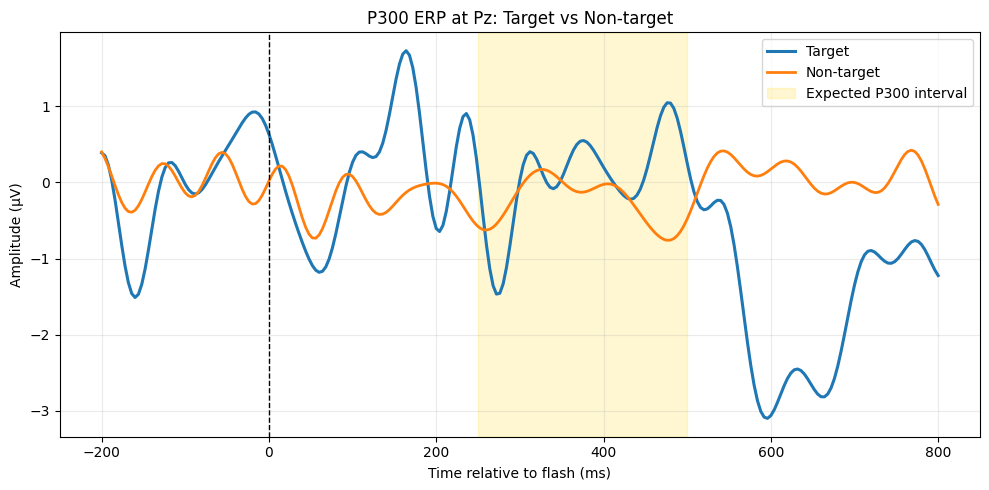


ERP temporal feature extraction completed successfully.


In [14]:
import matplotlib.pyplot as plt

erp_requested_channels = ["PZ", "P3", "P4", "POZ", "OZ"]
p300_epoch_lookup = {
    name.upper(): name for name in p300_epochs.ch_names
}

erp_channels = [
    p300_epoch_lookup[name]
    for name in erp_requested_channels
]

# Keep the required ERP channels and downsample temporal data to 25 Hz.
erp_epochs_downsampled = (
    p300_epochs.copy()
    .pick(erp_channels)
    .resample(25)
)

# Convert volts to microvolts and flatten:
# trials × channels × time -> trials × temporal features
X_erp_tensor = erp_epochs_downsampled.get_data() * 1e6
X_erp_all = X_erp_tensor.reshape(len(X_erp_tensor), -1)

# Binary labels used to inspect P300 target detection.
# 1 = Target, 0 = NonTarget
y_p300_binary = (
    erp_epochs_downsampled.events[:, 2]
    == p300_event_id["Target"]
).astype(int)

X_erp_target = X_erp_all[y_p300_binary == 1]
X_erp_nontarget = X_erp_all[y_p300_binary == 0]

erp_feature_names = [
    f"{channel}_{time_ms:.0f}ms"
    for channel in erp_channels
    for time_ms in erp_epochs_downsampled.times * 1000
]

print("ERP channels:", erp_channels)
print("Downsampled frequency:", erp_epochs_downsampled.info["sfreq"], "Hz")
print("ERP tensor shape:", X_erp_tensor.shape)
print("Flattened ERP feature matrix:", X_erp_all.shape)
print("Number of ERP feature names:", len(erp_feature_names))
print("Target feature matrix:", X_erp_target.shape)
print("Non-target feature matrix:", X_erp_nontarget.shape)

# Required Pz ERP waveform plot.
target_pz = (
    p300_epochs["Target"]
    .copy()
    .pick([p300_epoch_lookup["PZ"]])
    .average()
)

nontarget_pz = (
    p300_epochs["NonTarget"]
    .copy()
    .pick([p300_epoch_lookup["PZ"]])
    .average()
)

times_ms = target_pz.times * 1000

plt.figure(figsize=(10, 5))
plt.plot(
    times_ms,
    target_pz.data[0] * 1e6,
    label="Target",
    linewidth=2.2,
)
plt.plot(
    times_ms,
    nontarget_pz.data[0] * 1e6,
    label="Non-target",
    linewidth=2.0,
)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.axvspan(
    250,
    500,
    color="gold",
    alpha=0.18,
    label="Expected P300 interval",
)

plt.title("P300 ERP at Pz: Target vs Non-target")
plt.xlabel("Time relative to flash (ms)")
plt.ylabel("Amplitude (µV)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

assert X_erp_all.shape[1] == len(erp_feature_names)
assert np.isfinite(X_erp_all).all()

print("\nERP temporal feature extraction completed successfully.")

### Extract Rest/Idle CSP features

In [15]:
rest_csp_blocks = []
rest_epochs_by_band = {}

for band_name, (low_freq, high_freq) in filter_bands.items():
    band_raw = mi_filterbank_raw.copy().filter(
        l_freq=low_freq,
        h_freq=high_freq,
        method="fir",
        phase="zero",
        fir_design="firwin",
        verbose=False,
    )

    rest_epochs_band = mne.Epochs(
        band_raw,
        events=filterbank_events,
        event_id=mi_event_id,
        tmin=-1.5,
        tmax=-0.004,
        baseline=None,
        preload=True,
        reject_by_annotation=True,
        event_repeated="drop",
        verbose=False,
    )

    X_rest_band = rest_epochs_band.get_data()

    # Transform Rest data using the CSP model already learned
    # from left-versus-right motor imagery.
    rest_band_features = csp_models[band_name].transform(
        X_rest_band
    )

    rest_epochs_by_band[band_name] = rest_epochs_band
    rest_csp_blocks.append(rest_band_features)

    print(
        f"{band_name}: "
        f"{X_rest_band.shape} -> {rest_band_features.shape}"
    )

X_rest_csp = np.concatenate(rest_csp_blocks, axis=1)

print("\nRest CSP feature matrix:", X_rest_csp.shape)
print("MI CSP feature matrix:", X_mi_csp.shape)

assert X_rest_csp.shape[1] == X_mi_csp.shape[1]
assert np.isfinite(X_rest_csp).all()

print("\nRest/Idle CSP extraction completed successfully.")

mu_8_12: (40, 32, 375) -> (40, 6)
low_beta_12_16: (40, 32, 375) -> (40, 6)
beta_16_20: (40, 32, 375) -> (40, 6)
beta_20_24: (40, 32, 375) -> (40, 6)
high_beta_24_30: (40, 32, 375) -> (40, 6)

Rest CSP feature matrix: (40, 30)
MI CSP feature matrix: (40, 30)

Rest/Idle CSP extraction completed successfully.


### Prepare a low-frequency copy of the MI recording for temporal features.


In [16]:
mi_temporal_raw = raw_mi.copy().pick(selected_channels)

mi_temporal_raw, mi_temporal_events = mi_temporal_raw.resample(
    250,
    events=mi_events,
)

mi_temporal_raw.filter(
    l_freq=0.5,
    h_freq=15.0,
    method="fir",
    phase="zero",
    fir_design="firwin",
    verbose=False,
)

# Cue-locked temporal features for Left/Right MI.
mi_temporal_epochs = mne.Epochs(
    mi_temporal_raw,
    events=mi_temporal_events,
    event_id=mi_event_id,
    tmin=-0.2,
    tmax=0.8,
    baseline=(-0.2, 0.0),
    preload=True,
    event_repeated="drop",
    verbose=False,
)

# Pre-cue fixation window for Rest/Idle temporal features.
rest_temporal_epochs = mne.Epochs(
    mi_temporal_raw,
    events=mi_temporal_events,
    event_id=mi_event_id,
    tmin=-1.2,
    tmax=-0.2,
    baseline=(-1.2, -1.0),
    preload=True,
    event_repeated="drop",
    verbose=False,
)

# Retain the same five channels and 25-Hz temporal resolution.
mi_temporal_small = (
    mi_temporal_epochs.copy()
    .pick(erp_channels)
    .resample(25)
)

rest_temporal_small = (
    rest_temporal_epochs.copy()
    .pick(erp_channels)
    .resample(25)
)

X_mi_erp_tensor = mi_temporal_small.get_data() * 1e6
X_rest_erp_tensor = rest_temporal_small.get_data() * 1e6

X_mi_erp = X_mi_erp_tensor.reshape(
    len(X_mi_erp_tensor),
    -1,
)

X_rest_erp = X_rest_erp_tensor.reshape(
    len(X_rest_erp_tensor),
    -1,
)

# Confirm that MI labels remain in exactly the same trial order.
y_mi_temporal = mi_temporal_small.events[:, 2] - 1

assert np.array_equal(y_mi, y_mi_temporal)
assert X_mi_erp.shape[1] == X_erp_all.shape[1]
assert X_rest_erp.shape[1] == X_erp_all.shape[1]
assert np.isfinite(X_mi_erp).all()
assert np.isfinite(X_rest_erp).all()

print("MI temporal tensor:", X_mi_erp_tensor.shape)
print("Rest temporal tensor:", X_rest_erp_tensor.shape)
print("MI ERP-style features:", X_mi_erp.shape)
print("Rest ERP-style features:", X_rest_erp.shape)
print("Reference P300 features:", X_erp_all.shape)
print("\nTemporal feature dimensions are aligned.")

MI temporal tensor: (40, 5, 25)
Rest temporal tensor: (40, 5, 25)
MI ERP-style features: (40, 125)
Rest ERP-style features: (40, 125)
Reference P300 features: (724, 125)

Temporal feature dimensions are aligned.


### Prepare the P300 recording for filter-bank processing.


In [17]:
p300_filterbank_raw = raw_p300.copy().pick(
    p300_selected_channels
)

p300_filterbank_raw, p300_filterbank_events = (
    p300_filterbank_raw.resample(
        250,
        events=p300_events,
    )
)

p300_csp_blocks = []
p300_filterbank_event_codes = None

for band_name, (low_freq, high_freq) in filter_bands.items():
    p300_band_raw = p300_filterbank_raw.copy().filter(
        l_freq=low_freq,
        h_freq=high_freq,
        method="fir",
        phase="zero",
        fir_design="firwin",
        verbose=False,
    )

    p300_band_epochs = mne.Epochs(
        p300_band_raw,
        events=p300_filterbank_events,
        event_id=p300_event_id,
        tmin=0.0,
        tmax=0.8,
        baseline=None,
        preload=True,
        reject_by_annotation=True,
        event_repeated="drop",
        verbose=False,
    )

    X_p300_band = p300_band_epochs.get_data()

    if p300_filterbank_event_codes is None:
        p300_filterbank_event_codes = (
            p300_band_epochs.events[:, 2]
        )

    # Use the CSP model learned from the matching MI frequency band.
    p300_band_features = csp_models[band_name].transform(
        X_p300_band
    )

    p300_csp_blocks.append(p300_band_features)

    print(
        f"{band_name}: "
        f"{X_p300_band.shape} -> "
        f"{p300_band_features.shape}"
    )

X_p300_csp_all = np.concatenate(
    p300_csp_blocks,
    axis=1,
)

p300_target_mask = (
    p300_filterbank_event_codes
    == p300_event_id["Target"]
)

X_p300_target_csp = X_p300_csp_all[p300_target_mask]

assert X_p300_csp_all.shape[1] == X_mi_csp.shape[1]
assert len(X_p300_target_csp) == len(X_erp_target)
assert np.isfinite(X_p300_target_csp).all()

print("\nAll P300 CSP features:", X_p300_csp_all.shape)
print("Target-only CSP features:", X_p300_target_csp.shape)
print("Target ERP features:", X_erp_target.shape)
print("\nP300 feature dimensions are aligned.")

mu_8_12: (724, 32, 201) -> (724, 6)
low_beta_12_16: (724, 32, 201) -> (724, 6)
beta_16_20: (724, 32, 201) -> (724, 6)
beta_20_24: (724, 32, 201) -> (724, 6)
high_beta_24_30: (724, 32, 201) -> (724, 6)

All P300 CSP features: (724, 30)
Target-only CSP features: (120, 30)
Target ERP features: (120, 125)

P300 feature dimensions are aligned.


### Build the balanced four-class feature matrix

In [18]:
from collections import Counter

rng = np.random.default_rng(42)

samples_per_class = 20

# Verify that the P300 CSP and ERP event orders match.
assert np.array_equal(
    p300_filterbank_event_codes,
    p300_epochs.events[:, 2],
)

# Select balanced Rest and P300 subsets reproducibly.
rest_indices = rng.choice(
    len(X_rest_csp),
    size=samples_per_class,
    replace=False,
)

p300_indices = rng.choice(
    len(X_p300_target_csp),
    size=samples_per_class,
    replace=False,
)

left_mask = y_mi == 0
right_mask = y_mi == 1

# Combine CSP and ERP-style features for every class.
X_rest_hybrid = np.hstack([
    X_rest_csp[rest_indices],
    X_rest_erp[rest_indices],
])

X_left_hybrid = np.hstack([
    X_mi_csp[left_mask],
    X_mi_erp[left_mask],
])

X_right_hybrid = np.hstack([
    X_mi_csp[right_mask],
    X_mi_erp[right_mask],
])

X_p300_hybrid = np.hstack([
    X_p300_target_csp[p300_indices],
    X_erp_target[p300_indices],
])

X_hybrid = np.vstack([
    X_rest_hybrid,
    X_left_hybrid,
    X_right_hybrid,
    X_p300_hybrid,
])

y_hybrid = np.concatenate([
    np.full(samples_per_class, 0),
    np.full(samples_per_class, 1),
    np.full(samples_per_class, 2),
    np.full(samples_per_class, 3),
])

class_names = {
    0: "Rest/Idle",
    1: "Left-Hand MI",
    2: "Right-Hand MI",
    3: "P300 Target",
}

hybrid_feature_names = (
    csp_feature_names + erp_feature_names
)

# Shuffle samples while preserving feature-label alignment.
shuffle_indices = rng.permutation(len(y_hybrid))
X_hybrid = X_hybrid[shuffle_indices]
y_hybrid = y_hybrid[shuffle_indices]

print("Hybrid feature matrix:", X_hybrid.shape)
print("Hybrid label vector:", y_hybrid.shape)
print("Features per trial:", len(hybrid_feature_names))

print("\nClass distribution:")
for class_id, count in sorted(Counter(y_hybrid).items()):
    print(f"  {class_id} — {class_names[class_id]}: {count}")

assert X_hybrid.shape == (80, 155)
assert len(hybrid_feature_names) == 155
assert np.isfinite(X_hybrid).all()
assert set(y_hybrid) == {0, 1, 2, 3}

print("\nBalanced four-class dataset created successfully.")

Hybrid feature matrix: (80, 155)
Hybrid label vector: (80,)
Features per trial: 155

Class distribution:
  0 — Rest/Idle: 20
  1 — Left-Hand MI: 20
  2 — Right-Hand MI: 20
  3 — P300 Target: 20

Balanced four-class dataset created successfully.


### PCA 95% variance and top-20 Mutual Information

Original feature matrix: (80, 155)
PCA-reduced matrix: (80, 31)
Variance retained: 0.9520
Feature compression: 80.00%
Top-20 MI matrix: (80, 20)

Top five MI-ranked features:
  1. mu_8_12_CSP_3: 0.5092
  2. high_beta_24_30_CSP_2: 0.3884
  3. low_beta_12_16_CSP_2: 0.3325
  4. high_beta_24_30_CSP_4: 0.2766
  5. beta_20_24_CSP_2: 0.2555


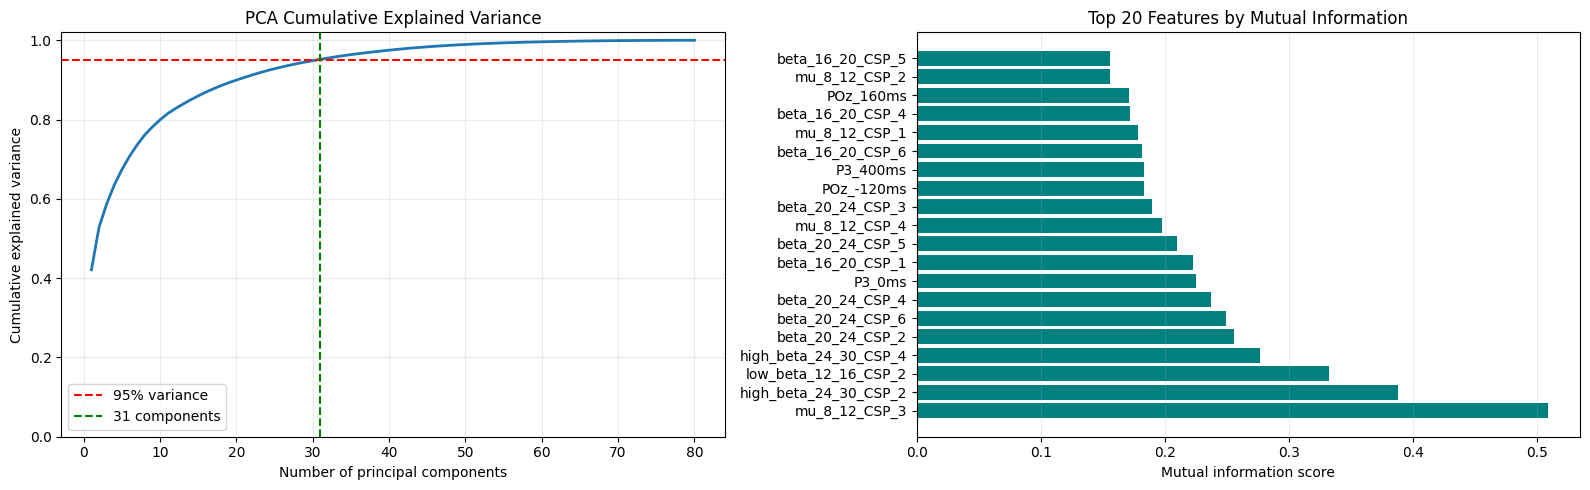


PCA and Mutual Information analysis completed.


In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif

# Standardize because CSP log-variance and ERP amplitude features
# have different numerical scales.
exploratory_scaler = StandardScaler()
X_hybrid_scaled = exploratory_scaler.fit_transform(X_hybrid)

# Fit full PCA for the cumulative-variance curve.
pca_full = PCA(svd_solver="full")
pca_full.fit(X_hybrid_scaled)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

# PCA retaining at least 95% cumulative variance.
pca_95 = PCA(
    n_components=0.95,
    svd_solver="full",
)

X_pca_95 = pca_95.fit_transform(X_hybrid_scaled)

retained_components = pca_95.n_components_
original_features = X_hybrid.shape[1]

compression_percent = (
    1 - retained_components / original_features
) * 100

# Mutual Information ranking.
mi_scores = mutual_info_classif(
    X_hybrid_scaled,
    y_hybrid,
    random_state=42,
)

top20_mi_indices = np.argsort(mi_scores)[::-1][:20]
top20_mi_names = [
    hybrid_feature_names[index]
    for index in top20_mi_indices
]
top20_mi_scores = mi_scores[top20_mi_indices]

X_mi_top20 = X_hybrid[:, top20_mi_indices]

print("Original feature matrix:", X_hybrid.shape)
print("PCA-reduced matrix:", X_pca_95.shape)
print(f"Variance retained: {pca_95.explained_variance_ratio_.sum():.4f}")
print(f"Feature compression: {compression_percent:.2f}%")
print("Top-20 MI matrix:", X_mi_top20.shape)

print("\nTop five MI-ranked features:")
for rank, (name, score) in enumerate(
    zip(top20_mi_names[:5], top20_mi_scores[:5]),
    start=1,
):
    print(f"  {rank}. {name}: {score:.4f}")

# Required dimensionality-reduction figures.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    linewidth=2,
)
axes[0].axhline(
    0.95,
    color="red",
    linestyle="--",
    label="95% variance",
)
axes[0].axvline(
    retained_components,
    color="green",
    linestyle="--",
    label=f"{retained_components} components",
)
axes[0].set_title("PCA Cumulative Explained Variance")
axes[0].set_xlabel("Number of principal components")
axes[0].set_ylabel("Cumulative explained variance")
axes[0].set_ylim(0, 1.02)
axes[0].grid(alpha=0.25)
axes[0].legend()

plot_order = np.arange(20)[::-1]

axes[1].barh(
    plot_order,
    top20_mi_scores[::-1],
    color="teal",
)
axes[1].set_yticks(
    plot_order,
    labels=top20_mi_names[::-1],
)
axes[1].set_title("Top 20 Features by Mutual Information")
axes[1].set_xlabel("Mutual information score")
axes[1].grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

assert pca_95.explained_variance_ratio_.sum() >= 0.95
assert X_mi_top20.shape == (80, 20)

print("\nPCA and Mutual Information analysis completed.")

### Five-fold benchmark of LDA, SVM, and k-NN

In [21]:
from functools import partial

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import (
    SelectKBest,
    mutual_info_classif,
)
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
)
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
)

# Outer five-fold evaluation.
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

# Inner folds used to select SVM and k-NN hyperparameters.
inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42,
)

mi_score_function = partial(
    mutual_info_classif,
    random_state=42,
)

# 1. LDA: standardized, PCA-reduced hybrid features.
lda_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    (
        "pca",
        PCA(
            n_components=0.95,
            svd_solver="full",
        ),
    ),
    (
        "classifier",
        LinearDiscriminantAnalysis(
            solver="lsqr",
            shrinkage="auto",
        ),
    ),
])

# 2. RBF-SVM: grid search over the required C values.
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    (
        "pca",
        PCA(
            n_components=0.95,
            svd_solver="full",
        ),
    ),
    (
        "classifier",
        SVC(
            kernel="rbf",
            gamma="scale",
            class_weight="balanced",
            probability=True,
            random_state=42,
        ),
    ),
])

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid={
        "classifier__C": [0.1, 1, 10],
    },
    scoring="f1_macro",
    cv=inner_cv,
    refit=True,
    n_jobs=-1,
)

# 3. k-NN: top-20 MI features, Manhattan distance,
# distance weighting, and grid search over k.
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    (
        "feature_selection",
        SelectKBest(
            score_func=mi_score_function,
            k=20,
        ),
    ),
    (
        "classifier",
        KNeighborsClassifier(
            metric="manhattan",
            weights="distance",
        ),
    ),
])

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid={
        "classifier__n_neighbors": [3, 5, 7],
    },
    scoring="f1_macro",
    cv=inner_cv,
    refit=True,
    n_jobs=-1,
)

classical_models = {
    "LDA": lda_pipeline,
    "SVM (RBF)": svm_search,
    "k-NN": knn_search,
}

classical_predictions = {}
classical_fold_details = {}
benchmark_rows = []

for model_name, estimator in classical_models.items():
    predictions = np.empty(
        shape=len(y_hybrid),
        dtype=int,
    )

    fold_details = []

    for fold_number, (train_indices, test_indices) in enumerate(
        outer_cv.split(X_hybrid, y_hybrid),
        start=1,
    ):
        fold_model = clone(estimator)

        fold_model.fit(
            X_hybrid[train_indices],
            y_hybrid[train_indices],
        )

        predictions[test_indices] = fold_model.predict(
            X_hybrid[test_indices]
        )

        detail = {"fold": fold_number}

        if isinstance(fold_model, GridSearchCV):
            detail["best_parameters"] = (
                fold_model.best_params_
            )
            detail["inner_macro_f1"] = (
                fold_model.best_score_
            )

        fold_details.append(detail)

    classical_predictions[model_name] = predictions
    classical_fold_details[model_name] = fold_details

    benchmark_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_hybrid,
            predictions,
        ),
        "Macro Precision": precision_score(
            y_hybrid,
            predictions,
            average="macro",
            zero_division=0,
        ),
        "Macro Recall": recall_score(
            y_hybrid,
            predictions,
            average="macro",
            zero_division=0,
        ),
        "Macro F1": f1_score(
            y_hybrid,
            predictions,
            average="macro",
            zero_division=0,
        ),
    })

classical_benchmark = (
    pd.DataFrame(benchmark_rows)
    .sort_values(
        by="Macro F1",
        ascending=False,
    )
    .reset_index(drop=True)
)

print("Classical model benchmark:")
display(
    classical_benchmark.style.format({
        "Accuracy": "{:.3f}",
        "Macro Precision": "{:.3f}",
        "Macro Recall": "{:.3f}",
        "Macro F1": "{:.3f}",
    })
)

for model_name, predictions in classical_predictions.items():
    print("\n" + "=" * 65)
    print(model_name)

    print(
        classification_report(
            y_hybrid,
            predictions,
            labels=[0, 1, 2, 3],
            target_names=[
                class_names[class_id]
                for class_id in range(4)
            ],
            digits=3,
            zero_division=0,
        )
    )

print("\nSelected grid-search parameters by fold:")

for model_name in ["SVM (RBF)", "k-NN"]:
    print(f"\n{model_name}:")

    for detail in classical_fold_details[model_name]:
        print(
            f"  Fold {detail['fold']}: "
            f"{detail['best_parameters']}, "
            f"inner Macro F1 = "
            f"{detail['inner_macro_f1']:.3f}"
        )

Classical model benchmark:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,SVM (RBF),0.575,0.579,0.575,0.576
1,LDA,0.588,0.577,0.587,0.575
2,k-NN,0.562,0.603,0.562,0.531



LDA
               precision    recall  f1-score   support

    Rest/Idle      0.312     0.250     0.278        20
 Left-Hand MI      0.583     0.700     0.636        20
Right-Hand MI      0.680     0.850     0.756        20
  P300 Target      0.733     0.550     0.629        20

     accuracy                          0.588        80
    macro avg      0.577     0.587     0.575        80
 weighted avg      0.577     0.588     0.575        80


SVM (RBF)
               precision    recall  f1-score   support

    Rest/Idle      0.381     0.400     0.390        20
 Left-Hand MI      0.632     0.600     0.615        20
Right-Hand MI      0.636     0.700     0.667        20
  P300 Target      0.667     0.600     0.632        20

     accuracy                          0.575        80
    macro avg      0.579     0.575     0.576        80
 weighted avg      0.579     0.575     0.576        80


k-NN
               precision    recall  f1-score   support

    Rest/Idle      0.182     0.100  

### Build the raw EEG tensor for EEGNet

In [22]:
# -----------------------------
# MI and Rest EEGNet windows
# -----------------------------

mi_eegnet_raw = raw_mi.copy().pick(selected_channels)

mi_eegnet_raw, mi_eegnet_events = mi_eegnet_raw.resample(
    250,
    events=mi_events,
)

mi_eegnet_raw.filter(
    l_freq=0.5,
    h_freq=40.0,
    method="fir",
    phase="zero",
    fir_design="firwin",
    verbose=False,
)

# One-second MI window during established imagery.
mi_eegnet_epochs = mne.Epochs(
    mi_eegnet_raw,
    events=mi_eegnet_events,
    event_id=mi_event_id,
    tmin=0.5,
    tmax=1.496,
    baseline=None,
    preload=True,
    event_repeated="drop",
    verbose=False,
)

# One-second pre-cue Rest/Idle window.
rest_eegnet_epochs = mne.Epochs(
    mi_eegnet_raw,
    events=mi_eegnet_events,
    event_id=mi_event_id,
    tmin=-1.0,
    tmax=-0.004,
    baseline=None,
    preload=True,
    event_repeated="drop",
    verbose=False,
)

X_mi_eegnet_all = (
    mi_eegnet_epochs.get_data() * 1e6
)

X_rest_eegnet_all = (
    rest_eegnet_epochs.get_data() * 1e6
)

mi_eegnet_labels = (
    mi_eegnet_epochs.events[:, 2] - 1
)

assert np.array_equal(mi_eegnet_labels, y_mi)

# -----------------------------
# P300 EEGNet windows
# -----------------------------

p300_eegnet_raw = raw_p300.copy().pick(
    p300_selected_channels
)

p300_eegnet_raw, p300_eegnet_events = (
    p300_eegnet_raw.resample(
        250,
        events=p300_events,
    )
)

p300_eegnet_raw.filter(
    l_freq=0.5,
    h_freq=40.0,
    method="fir",
    phase="zero",
    fir_design="firwin",
    verbose=False,
)

# One-second P300 epoch: -0.2 to 0.796 seconds.
p300_eegnet_epochs = mne.Epochs(
    p300_eegnet_raw,
    events=p300_eegnet_events,
    event_id=p300_event_id,
    tmin=-0.2,
    tmax=0.796,
    baseline=(-0.2, 0.0),
    preload=True,
    event_repeated="drop",
    verbose=False,
)

p300_eegnet_codes = (
    p300_eegnet_epochs.events[:, 2]
)

p300_eegnet_target_mask = (
    p300_eegnet_codes
    == p300_event_id["Target"]
)

X_p300_eegnet_targets = (
    p300_eegnet_epochs.get_data()[
        p300_eegnet_target_mask
    ] * 1e6
)

# -----------------------------
# Balanced four-class tensor
# -----------------------------

X_eegnet = np.concatenate([
    X_rest_eegnet_all[rest_indices],
    X_mi_eegnet_all[mi_eegnet_labels == 0],
    X_mi_eegnet_all[mi_eegnet_labels == 1],
    X_p300_eegnet_targets[p300_indices],
], axis=0)

y_eegnet = np.concatenate([
    np.full(samples_per_class, 0),
    np.full(samples_per_class, 1),
    np.full(samples_per_class, 2),
    np.full(samples_per_class, 3),
])

# Apply the same deterministic shuffle used for the feature dataset.
X_eegnet = X_eegnet[shuffle_indices]
y_eegnet = y_eegnet[shuffle_indices]

print("EEGNet tensor:", X_eegnet.shape)
print("EEGNet labels:", y_eegnet.shape)
print("Sampling frequency: 250 Hz")
print("Window duration: 1 second")

print("\nClass distribution:")
for class_id, count in sorted(Counter(y_eegnet).items()):
    print(
        f"  {class_id} — "
        f"{class_names[class_id]}: {count}"
    )

assert X_eegnet.shape == (80, 32, 250)
assert np.array_equal(y_eegnet, y_hybrid)
assert np.isfinite(X_eegnet).all()

print("\nEEGNet input tensor created successfully.")

EEGNet tensor: (80, 32, 250)
EEGNet labels: (80,)
Sampling frequency: 250 Hz
Window duration: 1 second

Class distribution:
  0 — Rest/Idle: 20
  1 — Left-Hand MI: 20
  2 — Right-Hand MI: 20
  3 — P300 Target: 20

EEGNet input tensor created successfully.


### Define and evaluate EEGNet with five-fold CV

In [23]:
import copy
import random

import torch
import torch.nn as nn
from torch.utils.data import (
    DataLoader,
    TensorDataset,
)
from sklearn.model_selection import StratifiedShuffleSplit

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", device)


def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class EEGNet(nn.Module):
    def __init__(
        self,
        n_channels=32,
        n_samples=250,
        n_classes=4,
        F1=8,
        D=2,
        dropout=0.5,
    ):
        super().__init__()

        F2 = F1 * D

        self.features = nn.Sequential(
            # Temporal convolution
            nn.Conv2d(
                in_channels=1,
                out_channels=F1,
                kernel_size=(1, 64),
                padding="same",
                bias=False,
            ),
            nn.BatchNorm2d(F1),

            # Depthwise spatial convolution
            nn.Conv2d(
                in_channels=F1,
                out_channels=F2,
                kernel_size=(n_channels, 1),
                groups=F1,
                bias=False,
            ),
            nn.BatchNorm2d(F2),
            nn.ELU(),
            nn.AvgPool2d(kernel_size=(1, 4)),
            nn.Dropout(dropout),

            # Depthwise temporal part of separable convolution
            nn.Conv2d(
                in_channels=F2,
                out_channels=F2,
                kernel_size=(1, 16),
                padding="same",
                groups=F2,
                bias=False,
            ),

            # Pointwise part of separable convolution
            nn.Conv2d(
                in_channels=F2,
                out_channels=F2,
                kernel_size=(1, 1),
                bias=False,
            ),
            nn.BatchNorm2d(F2),
            nn.ELU(),
            nn.AvgPool2d(kernel_size=(1, 8)),
            nn.Dropout(dropout),
        )

        # Determine classifier input size automatically.
        with torch.no_grad():
            dummy = torch.zeros(
                1,
                1,
                n_channels,
                n_samples,
            )
            flattened_size = (
                self.features(dummy)
                .flatten(start_dim=1)
                .shape[1]
            )

        self.classifier = nn.Linear(
            flattened_size,
            n_classes,
        )

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(start_dim=1)
        return self.classifier(x)


def predict_eegnet(model, loader):
    model.eval()
    predictions = []

    with torch.no_grad():
        for batch_x, _ in loader:
            logits = model(batch_x.to(device))
            batch_predictions = (
                logits.argmax(dim=1)
                .cpu()
                .numpy()
            )
            predictions.extend(batch_predictions)

    return np.asarray(predictions)


eegnet_predictions = np.empty(
    len(y_eegnet),
    dtype=int,
)

eegnet_fold_results = []

for fold_number, (train_val_idx, test_idx) in enumerate(
    outer_cv.split(X_eegnet, y_eegnet),
    start=1,
):
    fold_seed = 100 + fold_number
    set_all_seeds(fold_seed)

    # Create an internal validation split from the training fold.
    validation_splitter = StratifiedShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=fold_seed,
    )

    relative_train_idx, relative_val_idx = next(
        validation_splitter.split(
            X_eegnet[train_val_idx],
            y_eegnet[train_val_idx],
        )
    )

    train_idx = train_val_idx[relative_train_idx]
    val_idx = train_val_idx[relative_val_idx]

    # Normalize each channel using training data only.
    channel_mean = X_eegnet[train_idx].mean(
        axis=(0, 2),
        keepdims=True,
    )

    channel_std = X_eegnet[train_idx].std(
        axis=(0, 2),
        keepdims=True,
    )

    channel_std = np.maximum(channel_std, 1e-6)

    def normalize(indices):
        normalized = (
            X_eegnet[indices] - channel_mean
        ) / channel_std

        # Add the Conv2D input-channel dimension.
        return normalized[:, None, :, :].astype(
            np.float32
        )

    X_train = normalize(train_idx)
    X_val = normalize(val_idx)
    X_test = normalize(test_idx)

    y_train = y_eegnet[train_idx].astype(np.int64)
    y_val = y_eegnet[val_idx].astype(np.int64)
    y_test = y_eegnet[test_idx].astype(np.int64)

    train_loader = DataLoader(
        TensorDataset(
            torch.from_numpy(X_train),
            torch.from_numpy(y_train),
        ),
        batch_size=16,
        shuffle=True,
    )

    val_loader = DataLoader(
        TensorDataset(
            torch.from_numpy(X_val),
            torch.from_numpy(y_val),
        ),
        batch_size=32,
        shuffle=False,
    )

    test_loader = DataLoader(
        TensorDataset(
            torch.from_numpy(X_test),
            torch.from_numpy(y_test),
        ),
        batch_size=32,
        shuffle=False,
    )

    model = EEGNet(
        n_channels=32,
        n_samples=250,
        n_classes=4,
        F1=8,
        D=2,
        dropout=0.5,
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4,
    )

    best_validation_loss = np.inf
    best_state = None
    patience = 15
    epochs_without_improvement = 0
    maximum_epochs = 120
    epochs_completed = 0

    for epoch in range(maximum_epochs):
        model.train()

        for batch_x, batch_y in train_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()
            logits = model(batch_x)
            loss = criterion(logits, batch_y)
            loss.backward()
            optimizer.step()

        # Validation loss
        model.eval()
        validation_losses = []

        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x = batch_x.to(device)
                batch_y = batch_y.to(device)

                logits = model(batch_x)
                validation_losses.append(
                    criterion(logits, batch_y).item()
                )

        mean_validation_loss = np.mean(
            validation_losses
        )

        epochs_completed = epoch + 1

        if mean_validation_loss < (
            best_validation_loss - 1e-4
        ):
            best_validation_loss = (
                mean_validation_loss
            )
            best_state = copy.deepcopy(
                model.state_dict()
            )
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    model.load_state_dict(best_state)

    fold_predictions = predict_eegnet(
        model,
        test_loader,
    )

    eegnet_predictions[test_idx] = fold_predictions

    fold_accuracy = accuracy_score(
        y_test,
        fold_predictions,
    )

    fold_macro_f1 = f1_score(
        y_test,
        fold_predictions,
        average="macro",
        zero_division=0,
    )

    eegnet_fold_results.append({
        "fold": fold_number,
        "epochs": epochs_completed,
        "accuracy": fold_accuracy,
        "macro_f1": fold_macro_f1,
    })

    print(
        f"Fold {fold_number}: "
        f"epochs={epochs_completed}, "
        f"accuracy={fold_accuracy:.3f}, "
        f"Macro F1={fold_macro_f1:.3f}"
    )

eegnet_row = {
    "Model": "EEGNet",
    "Accuracy": accuracy_score(
        y_eegnet,
        eegnet_predictions,
    ),
    "Macro Precision": precision_score(
        y_eegnet,
        eegnet_predictions,
        average="macro",
        zero_division=0,
    ),
    "Macro Recall": recall_score(
        y_eegnet,
        eegnet_predictions,
        average="macro",
        zero_division=0,
    ),
    "Macro F1": f1_score(
        y_eegnet,
        eegnet_predictions,
        average="macro",
        zero_division=0,
    ),
}

benchmark_table = pd.concat(
    [
        classical_benchmark,
        pd.DataFrame([eegnet_row]),
    ],
    ignore_index=True,
).sort_values(
    "Macro F1",
    ascending=False,
).reset_index(drop=True)

all_predictions = dict(classical_predictions)
all_predictions["EEGNet"] = eegnet_predictions

print("\nUnified four-model benchmark:")
display(
    benchmark_table.style.format({
        "Accuracy": "{:.3f}",
        "Macro Precision": "{:.3f}",
        "Macro Recall": "{:.3f}",
        "Macro F1": "{:.3f}",
    })
)

print("\nEEGNet classification report:")
print(
    classification_report(
        y_eegnet,
        eegnet_predictions,
        labels=[0, 1, 2, 3],
        target_names=[
            class_names[class_id]
            for class_id in range(4)
        ],
        digits=3,
        zero_division=0,
    )
)

Training device: cuda


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1104.)
  return F.conv2d(


Fold 1: epochs=56, accuracy=0.250, Macro F1=0.217
Fold 2: epochs=25, accuracy=0.312, Macro F1=0.271
Fold 3: epochs=39, accuracy=0.250, Macro F1=0.226
Fold 4: epochs=92, accuracy=0.125, Macro F1=0.083
Fold 5: epochs=27, accuracy=0.188, Macro F1=0.163

Unified four-model benchmark:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,SVM (RBF),0.575,0.579,0.575,0.576
1,LDA,0.588,0.577,0.587,0.575
2,k-NN,0.562,0.603,0.562,0.531
3,EEGNet,0.225,0.228,0.225,0.222



EEGNet classification report:
               precision    recall  f1-score   support

    Rest/Idle      0.150     0.150     0.150        20
 Left-Hand MI      0.333     0.250     0.286        20
Right-Hand MI      0.241     0.350     0.286        20
  P300 Target      0.188     0.150     0.167        20

     accuracy                          0.225        80
    macro avg      0.228     0.225     0.222        80
 weighted avg      0.228     0.225     0.222        80



### Normalized confusion matrix and confusion-pair analysis

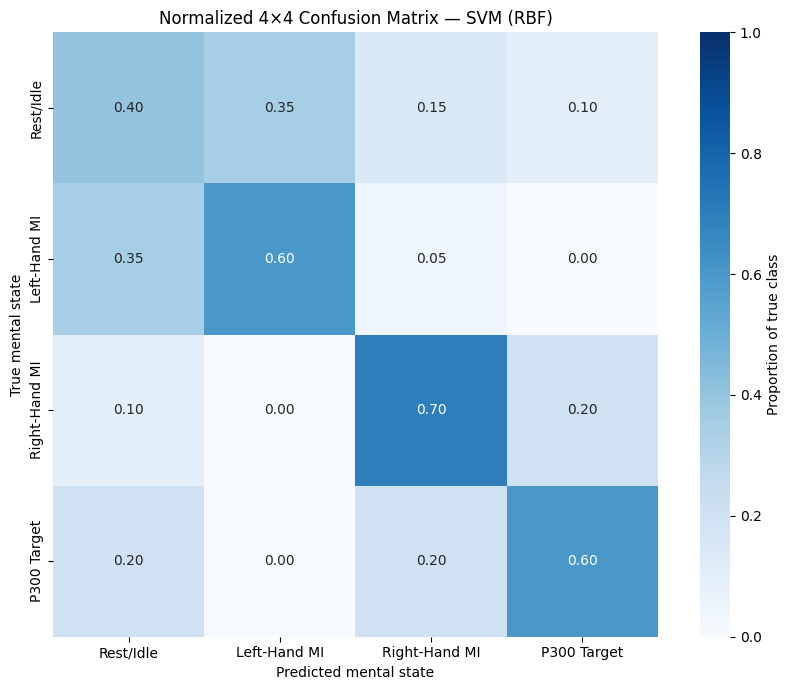

Selected model: SVM (RBF)

Cross-class confusion ranking:


,Class A,Class B,A predicted as B,B predicted as A,Mean cross-confusion
0,Rest/Idle,Left-Hand MI,0.350,0.350,0.350
1,Right-Hand MI,P300 Target,0.200,0.200,0.200
2,Rest/Idle,P300 Target,0.100,0.200,0.150
3,Rest/Idle,Right-Hand MI,0.150,0.100,0.125
4,Left-Hand MI,Right-Hand MI,0.050,0.000,0.025
5,Left-Hand MI,P300 Target,0.000,0.000,0.000



Highest-confusion pair: Rest/Idle and Left-Hand MI
Mean bidirectional confusion: 0.350


In [24]:
from sklearn.metrics import confusion_matrix

best_model_name = benchmark_table.iloc[0]["Model"]
best_predictions = all_predictions[best_model_name]

class_order = [0, 1, 2, 3]
class_labels = [
    class_names[class_id]
    for class_id in class_order
]

normalized_cm = confusion_matrix(
    y_hybrid,
    best_predictions,
    labels=class_order,
    normalize="true",
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    normalized_cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=class_labels,
    yticklabels=class_labels,
    square=True,
    cbar_kws={
        "label": "Proportion of true class",
    },
)

plt.title(
    f"Normalized 4×4 Confusion Matrix — "
    f"{best_model_name}"
)
plt.xlabel("Predicted mental state")
plt.ylabel("True mental state")
plt.tight_layout()
plt.show()

# Find the pair with the greatest bidirectional confusion.
pair_confusions = []

for first_class in range(4):
    for second_class in range(first_class + 1, 4):
        first_to_second = normalized_cm[
            first_class,
            second_class,
        ]

        second_to_first = normalized_cm[
            second_class,
            first_class,
        ]

        mean_bidirectional_confusion = (
            first_to_second + second_to_first
        ) / 2

        pair_confusions.append({
            "Class A": class_names[first_class],
            "Class B": class_names[second_class],
            "A predicted as B": first_to_second,
            "B predicted as A": second_to_first,
            "Mean cross-confusion": (
                mean_bidirectional_confusion
            ),
        })

pair_confusion_table = (
    pd.DataFrame(pair_confusions)
    .sort_values(
        "Mean cross-confusion",
        ascending=False,
    )
    .reset_index(drop=True)
)

print("Selected model:", best_model_name)
print("\nCross-class confusion ranking:")

display(
    pair_confusion_table.style.format({
        "A predicted as B": "{:.3f}",
        "B predicted as A": "{:.3f}",
        "Mean cross-confusion": "{:.3f}",
    })
)

highest_confusion = pair_confusion_table.iloc[0]

print(
    "\nHighest-confusion pair:",
    highest_confusion["Class A"],
    "and",
    highest_confusion["Class B"],
)

print(
    "Mean bidirectional confusion:",
    f"{highest_confusion['Mean cross-confusion']:.3f}",
)

### Locate and inspect the eye-tracking stream

In [25]:
from pathlib import Path

mne_data_root = Path("/root/mne_data")

tobii_files = sorted(
    mne_data_root.rglob("*_tobii.csv")
)

sync_files = sorted(
    mne_data_root.rglob("*_sync.csv")
)

print("Tobii eye-tracking files found:", len(tobii_files))

for index, path in enumerate(tobii_files):
    size_mb = path.stat().st_size / (1024**2)

    print(
        f"  [{index}] {path}\n"
        f"      Size: {size_mb:.2f} MB"
    )

print("\nSynchronization files found:", len(sync_files))

for index, path in enumerate(sync_files):
    size_mb = path.stat().st_size / (1024**2)

    print(
        f"  [{index}] {path}\n"
        f"      Size: {size_mb:.2f} MB"
    )

if not tobii_files:
    raise FileNotFoundError(
        "No Tobii CSV files were found in /root/mne_data."
    )

# Inspect the first eye-tracking file without loading it fully.
gaze_preview = pd.read_csv(
    tobii_files[0],
    nrows=5,
)

print("\nPreviewing:", tobii_files[0].name)
print("Columns:")
for column in gaze_preview.columns:
    print(" -", column)

print("\nFirst five rows:")
display(gaze_preview)

Tobii eye-tracking files found: 4
  [0] /root/mne_data/MNE-guttmannflury2025-data/MI/S01/Sess01/MI011_tobii.csv
      Size: 32.01 MB
  [1] /root/mne_data/MNE-guttmannflury2025-data/P3004L/S01/Sess01/P3004L011_tobii.csv
      Size: 54.19 MB
  [2] /root/mne_data/NEMAR/nm000136/sourcedata/S01/Sess01/P3004L011_tobii.csv
      Size: 54.19 MB
  [3] /root/mne_data/NEMAR/nm000265/sourcedata/S01/Sess01/MI011_tobii.csv
      Size: 32.01 MB

Synchronization files found: 4
  [0] /root/mne_data/MNE-guttmannflury2025-data/MI/S01/Sess01/MI011_sync.csv
      Size: 7.33 MB
  [1] /root/mne_data/MNE-guttmannflury2025-data/P3004L/S01/Sess01/P3004L011_sync.csv
      Size: 11.67 MB
  [2] /root/mne_data/NEMAR/nm000136/sourcedata/S01/Sess01/P3004L011_sync.csv
      Size: 11.67 MB
  [3] /root/mne_data/NEMAR/nm000265/sourcedata/S01/Sess01/MI011_sync.csv
      Size: 7.33 MB

Previewing: MI011_tobii.csv
Columns:
 - ExportDate
 - StudioVersionRec
 - StudioProjectName
 - StudioTestName
 - ParticipantName
 - Session

,ExportDate,StudioVersionRec,StudioProjectName,StudioTestName,ParticipantName,SessionName,RecordingName,RecordingDate,RecordingDuration,RecordingResolution,...,CamRightY,DistanceLeft,DistanceRight,PupilLeft,PupilRight,ValidityLeft,ValidityRight,IRMarkerCount,IRMarkerID,PupilGlassesRight
0,8/6/2018,3.4.8,NaN,NaN,S01,Sess01,MI011,8/6/2018,383075,1920 x 1080,...,NaN,NaN,NaN,NaN,NaN,4,4,NaN,NaN,NaN
1,8/6/2018,3.4.8,NaN,NaN,S01,Sess01,MI011,8/6/2018,383075,1920 x 1080,...,NaN,NaN,NaN,NaN,NaN,4,4,NaN,NaN,NaN
2,8/6/2018,3.4.8,NaN,NaN,S01,Sess01,MI011,8/6/2018,383075,1920 x 1080,...,NaN,NaN,NaN,NaN,NaN,4,4,NaN,NaN,NaN
3,8/6/2018,3.4.8,NaN,NaN,S01,Sess01,MI011,8/6/2018,383075,1920 x 1080,...,NaN,NaN,NaN,NaN,NaN,4,4,NaN,NaN,NaN
4,8/6/2018,3.4.8,NaN,NaN,S01,Sess01,MI011,8/6/2018,383075,1920 x 1080,...,NaN,NaN,NaN,NaN,NaN,4,4,NaN,NaN,NaN


### Load and summarize valid fixation data

In [26]:
# Select the extracted MI eye-tracking file, avoiding the duplicate NEMAR copy.
mi_tobii_file = next(
    path
    for path in tobii_files
    if "/MI/" in str(path).replace("\\", "/")
    and "/NEMAR/" not in str(path).replace("\\", "/")
)

gaze_columns = [
    "RecordingTimestamp",
    "GazeEventType",
    "GazeEventDuration",
    "FixationIndex",
    "FixationPointX (MCSpx)",
    "FixationPointY (MCSpx)",
    "GazePointX (MCSpx)",
    "GazePointY (MCSpx)",
    "ValidityLeft",
    "ValidityRight",
]

gaze_df = pd.read_csv(
    mi_tobii_file,
    usecols=gaze_columns,
    low_memory=False,
)

numeric_columns = [
    "RecordingTimestamp",
    "GazeEventDuration",
    "FixationIndex",
    "FixationPointX (MCSpx)",
    "FixationPointY (MCSpx)",
    "GazePointX (MCSpx)",
    "GazePointY (MCSpx)",
    "ValidityLeft",
    "ValidityRight",
]

for column in numeric_columns:
    gaze_df[column] = pd.to_numeric(
        gaze_df[column],
        errors="coerce",
    )

# Tobii validity codes 0 and 1 are usable; code 4 is invalid.
valid_eye_mask = (
    (gaze_df["ValidityLeft"] <= 1)
    | (gaze_df["ValidityRight"] <= 1)
)

fixation_mask = (
    gaze_df["GazeEventType"]
    .astype(str)
    .str.lower()
    .eq("fixation")
)

coordinate_mask = (
    gaze_df["FixationPointX (MCSpx)"].notna()
    & gaze_df["FixationPointY (MCSpx)"].notna()
)

valid_fixation_rows = gaze_df.loc[
    valid_eye_mask
    & fixation_mask
    & coordinate_mask
].copy()

print("Eye-tracking file:", mi_tobii_file.name)
print("Total gaze samples:", len(gaze_df))
print("Valid fixation rows:", len(valid_fixation_rows))
print(
    "Unique fixation events:",
    valid_fixation_rows["FixationIndex"].nunique(),
)

print("\nGaze-event counts:")
print(
    gaze_df["GazeEventType"]
    .value_counts(dropna=False)
    .head(10)
)

print("\nFixation-duration summary (ms):")
print(
    valid_fixation_rows["GazeEventDuration"]
    .describe()
)

print("\nFixation-coordinate summary:")
display(
    valid_fixation_rows[
        [
            "FixationPointX (MCSpx)",
            "FixationPointY (MCSpx)",
        ]
    ].describe()
)

print("\nExample valid fixation rows:")
display(
    valid_fixation_rows[
        [
            "RecordingTimestamp",
            "FixationIndex",
            "GazeEventDuration",
            "FixationPointX (MCSpx)",
            "FixationPointY (MCSpx)",
        ]
    ].head(10)
)

Eye-tracking file: MI011_tobii.csv
Total gaze samples: 115041
Valid fixation rows: 38145
Unique fixation events: 381

Gaze-event counts:
GazeEventType
Fixation        94394
Unclassified    15743
Saccade          4904
Name: count, dtype: int64

Fixation-duration summary (ms):
count    38145.000000
mean      2451.989199
std       1894.948386
min         60.000000
25%        797.000000
50%       1933.000000
75%       3793.000000
max       6633.000000
Name: GazeEventDuration, dtype: float64

Fixation-coordinate summary:


,FixationPointX (MCSpx),FixationPointY (MCSpx)
count,38145.000000,38145.000000
mean,489.129191,335.142509
std,89.679621,16.851087
min,27.000000,94.000000
25%,477.000000,329.000000
50%,483.000000,332.000000
75%,490.000000,339.000000
max,1057.000000,777.000000



Example valid fixation rows:


,RecordingTimestamp,FixationIndex,GazeEventDuration,FixationPointX (MCSpx),FixationPointY (MCSpx)
7086,23583,3.0,87,231.0,439.0
7087,23587,3.0,87,231.0,439.0
7089,23593,3.0,87,231.0,439.0
7104,23643,3.0,87,231.0,439.0
7105,23646,3.0,87,231.0,439.0
7106,23650,3.0,87,231.0,439.0
7107,23653,3.0,87,231.0,439.0
7108,23657,3.0,87,231.0,439.0
7109,23660,3.0,87,231.0,439.0
7110,23663,3.0,87,231.0,439.0


### Aggregate fixations and visualize candidate ROI

Unique fixation events: 381
Fixations lasting at least 400 ms: 164
Percentage lasting at least 400 ms: 43.0%

Candidate ROI: x = [360.0, 700.0], y = [319.0, 369.0]
Fixations inside candidate ROI: 262


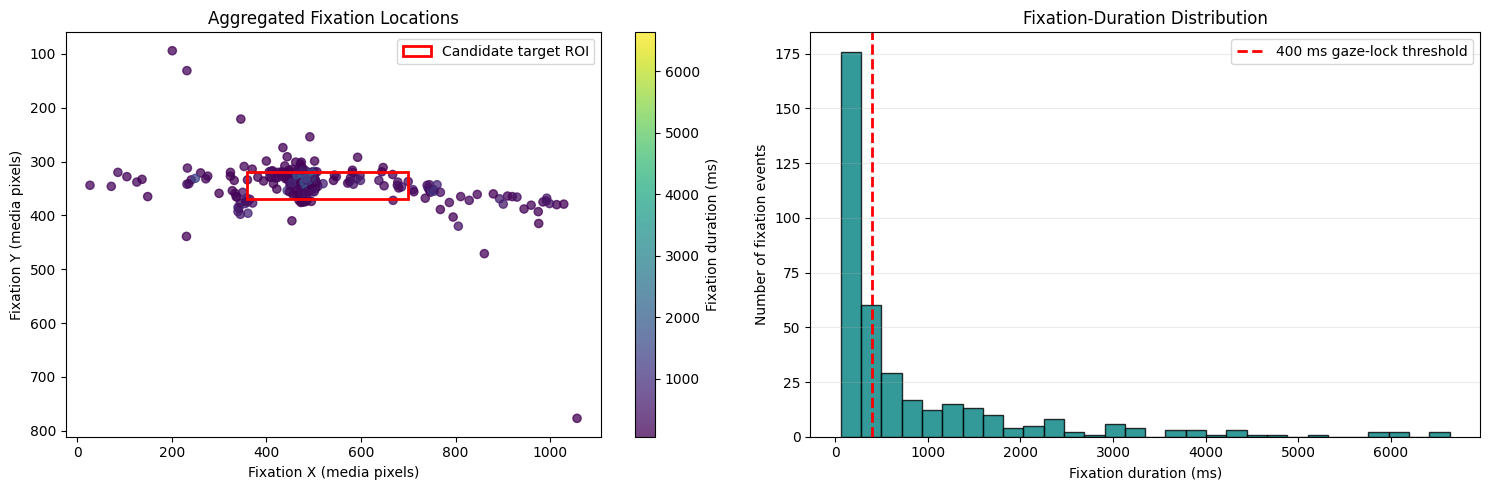

,FixationIndex,start_timestamp_ms,fixation_duration_ms,fixation_x,fixation_y,gaze_samples,time_seconds,passes_400ms,inside_candidate_roi
0,3.0,23583,87,231.0,439.0,11,0.000,False,False
1,4.0,23937,140,861.0,471.0,11,0.354,False,False
2,5.0,24120,67,544.0,325.0,7,0.537,False,True
3,6.0,24386,203,920.0,365.0,29,0.803,False,False
4,7.0,24657,200,572.0,340.0,36,1.074,False,True
5,8.0,24920,190,910.0,364.0,21,1.337,False,False
6,9.0,25186,193,668.0,372.0,22,1.603,False,False
7,10.0,25476,177,985.0,375.0,18,1.893,False,False
8,11.0,25703,207,649.0,345.0,28,2.120,False,True
9,12.0,25983,77,435.0,320.0,9,2.400,False,True


In [27]:
# Collapse repeated gaze samples into one row per fixation event.
fixation_events = (
    valid_fixation_rows
    .groupby("FixationIndex", as_index=False)
    .agg(
        start_timestamp_ms=(
            "RecordingTimestamp",
            "min",
        ),
        fixation_duration_ms=(
            "GazeEventDuration",
            "max",
        ),
        fixation_x=(
            "FixationPointX (MCSpx)",
            "median",
        ),
        fixation_y=(
            "FixationPointY (MCSpx)",
            "median",
        ),
        gaze_samples=(
            "RecordingTimestamp",
            "size",
        ),
    )
    .sort_values("start_timestamp_ms")
    .reset_index(drop=True)
)

# Express time relative to the first valid fixation.
fixation_events["time_seconds"] = (
    fixation_events["start_timestamp_ms"]
    - fixation_events["start_timestamp_ms"].min()
) / 1000

fixation_events["passes_400ms"] = (
    fixation_events["fixation_duration_ms"] >= 400
)

# Candidate central ROI based on robust 10th–90th percentiles.
x_low, x_high = fixation_events["fixation_x"].quantile(
    [0.10, 0.90]
)

y_low, y_high = fixation_events["fixation_y"].quantile(
    [0.10, 0.90]
)

fixation_events["inside_candidate_roi"] = (
    fixation_events["fixation_x"].between(
        x_low,
        x_high,
    )
    & fixation_events["fixation_y"].between(
        y_low,
        y_high,
    )
)

print("Unique fixation events:", len(fixation_events))
print(
    "Fixations lasting at least 400 ms:",
    fixation_events["passes_400ms"].sum(),
)
print(
    "Percentage lasting at least 400 ms:",
    f"{fixation_events['passes_400ms'].mean() * 100:.1f}%",
)

print(
    "\nCandidate ROI:",
    f"x = [{x_low:.1f}, {x_high:.1f}],",
    f"y = [{y_low:.1f}, {y_high:.1f}]",
)

print(
    "Fixations inside candidate ROI:",
    fixation_events["inside_candidate_roi"].sum(),
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

scatter = axes[0].scatter(
    fixation_events["fixation_x"],
    fixation_events["fixation_y"],
    c=fixation_events["fixation_duration_ms"],
    cmap="viridis",
    alpha=0.75,
    s=35,
)

roi_rectangle = plt.Rectangle(
    (x_low, y_low),
    x_high - x_low,
    y_high - y_low,
    fill=False,
    edgecolor="red",
    linewidth=2,
    label="Candidate target ROI",
)

axes[0].add_patch(roi_rectangle)
axes[0].invert_yaxis()
axes[0].set_title("Aggregated Fixation Locations")
axes[0].set_xlabel("Fixation X (media pixels)")
axes[0].set_ylabel("Fixation Y (media pixels)")
axes[0].legend()

plt.colorbar(
    scatter,
    ax=axes[0],
    label="Fixation duration (ms)",
)

axes[1].hist(
    fixation_events["fixation_duration_ms"],
    bins=30,
    color="teal",
    alpha=0.8,
    edgecolor="black",
)

axes[1].axvline(
    400,
    color="red",
    linestyle="--",
    linewidth=2,
    label="400 ms gaze-lock threshold",
)

axes[1].set_title("Fixation-Duration Distribution")
axes[1].set_xlabel("Fixation duration (ms)")
axes[1].set_ylabel("Number of fixation events")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

display(fixation_events.head(10))

### Implement the hybrid gaze–MI–P300 controller

In [28]:
# Candidate virtual-object ROI derived from the real fixation distribution.
TARGET_ROI_BOUNDS = {
    "x_min": float(x_low),
    "x_max": float(x_high),
    "y_min": float(y_low),
    "y_max": float(y_high),
}


def assign_gaze_roi(fixation_x, fixation_y):
    """Return ROI 1 for the target region and 0 for background."""
    inside_target = (
        TARGET_ROI_BOUNDS["x_min"]
        <= fixation_x
        <= TARGET_ROI_BOUNDS["x_max"]
        and TARGET_ROI_BOUNDS["y_min"]
        <= fixation_y
        <= TARGET_ROI_BOUNDS["y_max"]
    )

    return 1 if inside_target else 0


controller_memory = {
    "trajectory_armed": False,
    "active_roi": 0,
    "trajectory": None,
}


def reset_hybrid_controller():
    controller_memory["trajectory_armed"] = False
    controller_memory["active_roi"] = 0
    controller_memory["trajectory"] = None


def hybrid_vr_controller(
    eeg_probs,
    gaze_roi,
    fixation_duration_ms,
    confidence_thresh=0.75,
):
    """
    eeg_probs:
        [P(Rest), P(Left_MI), P(Right_MI), P(P300)]

    gaze_roi:
        0 = background, >0 = valid prosthetic target

    fixation_duration_ms:
        Continuous dwell duration on the current ROI.
    """
    eeg_probs = np.asarray(eeg_probs, dtype=float)

    if eeg_probs.shape != (4,):
        raise ValueError(
            "eeg_probs must contain exactly four probabilities."
        )

    if not np.isclose(eeg_probs.sum(), 1.0, atol=1e-3):
        raise ValueError(
            "eeg_probs must sum to approximately 1."
        )

    gaze_locked = (
        gaze_roi > 0
        and fixation_duration_ms >= 400
    )

    # State 1: system remains locked without valid gaze.
    if not gaze_locked:
        reset_hybrid_controller()

        return {
            "state": "LOCKED",
            "action": "NO_ACTION",
            "gaze_locked": False,
            "confidence": float(eeg_probs.max()),
        }

    # Changing the selected object resets any prior trajectory.
    if (
        controller_memory["active_roi"] != 0
        and controller_memory["active_roi"] != gaze_roi
    ):
        controller_memory["trajectory_armed"] = False
        controller_memory["trajectory"] = None

    controller_memory["active_roi"] = gaze_roi

    # State 3: P300 can close the gripper only after MI movement.
    if (
        controller_memory["trajectory_armed"]
        and eeg_probs[3] >= confidence_thresh
    ):
        previous_trajectory = controller_memory["trajectory"]

        controller_memory["trajectory_armed"] = False
        controller_memory["trajectory"] = None

        return {
            "state": "GRASP_CONFIRMED",
            "action": "CLOSE_GRIPPER",
            "gaze_locked": True,
            "roi": gaze_roi,
            "trajectory": previous_trajectory,
            "confidence": float(eeg_probs[3]),
        }

    # State 2: choose the stronger MI direction.
    left_probability = eeg_probs[1]
    right_probability = eeg_probs[2]

    if (
        left_probability >= confidence_thresh
        and left_probability > right_probability
    ):
        controller_memory["trajectory_armed"] = True
        controller_memory["trajectory"] = "LEFT"

        return {
            "state": "MOVEMENT_ARMED",
            "action": "MOVE_LEFT",
            "gaze_locked": True,
            "roi": gaze_roi,
            "confidence": float(left_probability),
        }

    if (
        right_probability >= confidence_thresh
        and right_probability > left_probability
    ):
        controller_memory["trajectory_armed"] = True
        controller_memory["trajectory"] = "RIGHT"

        return {
            "state": "MOVEMENT_ARMED",
            "action": "MOVE_RIGHT",
            "gaze_locked": True,
            "roi": gaze_roi,
            "confidence": float(right_probability),
        }

    if controller_memory["trajectory_armed"]:
        state = "WAITING_FOR_P300"
    else:
        state = "GAZE_LOCKED_WAITING_FOR_MI"

    return {
        "state": state,
        "action": "NO_ACTION",
        "gaze_locked": True,
        "roi": gaze_roi,
        "confidence": float(eeg_probs.max()),
    }


# -----------------------------
# Controller sequence test
# -----------------------------

reset_hybrid_controller()

test_sequence = [
    {
        "description": "Insufficient gaze dwell",
        "probs": [0.80, 0.08, 0.07, 0.05],
        "roi": 1,
        "dwell": 200,
    },
    {
        "description": "Left MI trajectory",
        "probs": [0.05, 0.82, 0.08, 0.05],
        "roi": 1,
        "dwell": 650,
    },
    {
        "description": "P300 grasp confirmation",
        "probs": [0.05, 0.07, 0.07, 0.81],
        "roi": 1,
        "dwell": 700,
    },
]

for test in test_sequence:
    result = hybrid_vr_controller(
        eeg_probs=test["probs"],
        gaze_roi=test["roi"],
        fixation_duration_ms=test["dwell"],
    )

    print(
        f"{test['description']}: "
        f"{result['state']} -> {result['action']}"
    )

Insufficient gaze dwell: LOCKED -> NO_ACTION
Left MI trajectory: MOVEMENT_ARMED -> MOVE_LEFT
P300 grasp confirmation: GRASP_CONFIRMED -> CLOSE_GRIPPER


### Generate out-of-fold EEG probabilities

In [29]:
svm_oof_probs = np.zeros(
    (len(y_hybrid), 4),
    dtype=float,
)

svm_oof_predictions = np.empty(
    len(y_hybrid),
    dtype=int,
)

svm_probability_fold_details = []

for fold_number, (train_indices, test_indices) in enumerate(
    outer_cv.split(X_hybrid, y_hybrid),
    start=1,
):
    fold_model = clone(svm_search)

    fold_model.fit(
        X_hybrid[train_indices],
        y_hybrid[train_indices],
    )

    fold_probabilities = fold_model.predict_proba(
        X_hybrid[test_indices]
    )

    # Reorder probability columns explicitly into classes 0, 1, 2, 3.
    ordered_probabilities = np.zeros(
        (len(test_indices), 4),
        dtype=float,
    )

    for probability_column, class_id in enumerate(
        fold_model.classes_
    ):
        ordered_probabilities[:, int(class_id)] = (
            fold_probabilities[:, probability_column]
        )

    svm_oof_probs[test_indices] = ordered_probabilities
    svm_oof_predictions[test_indices] = (
        ordered_probabilities.argmax(axis=1)
    )

    svm_probability_fold_details.append({
        "fold": fold_number,
        "best_C": fold_model.best_params_[
            "classifier__C"
        ],
    })

# Also fit a final model on all samples for later deployment examples.
final_svm_model = clone(svm_search)
final_svm_model.fit(X_hybrid, y_hybrid)

maximum_confidences = svm_oof_probs.max(axis=1)

print("OOF probability matrix:", svm_oof_probs.shape)
print(
    "All rows sum to one:",
    np.allclose(svm_oof_probs.sum(axis=1), 1.0),
)
print(
    "OOF probability accuracy:",
    f"{accuracy_score(y_hybrid, svm_oof_predictions):.3f}",
)
print(
    "OOF probability Macro F1:",
    f"{f1_score(y_hybrid, svm_oof_predictions, average='macro'):.3f}",
)

print("\nMaximum-confidence summary:")
print(pd.Series(maximum_confidences).describe())

print(
    "\nSamples with confidence ≥ 0.75:",
    int(np.sum(maximum_confidences >= 0.75)),
    "out of",
    len(maximum_confidences),
)

print(
    "Final full-data SVM parameters:",
    final_svm_model.best_params_,
)

assert svm_oof_probs.shape == (80, 4)
assert np.allclose(
    svm_oof_probs.sum(axis=1),
    1.0,
    atol=1e-6,
)

print("\nOut-of-fold probability templates are ready.")

OOF probability matrix: (80, 4)
All rows sum to one: True
OOF probability accuracy: 0.562
OOF probability Macro F1: 0.560

Maximum-confidence summary:
count    80.000000
mean      0.509108
std       0.109145
min       0.288165
25%       0.433179
50%       0.498742
75%       0.577718
max       0.791075
dtype: float64

Samples with confidence ≥ 0.75: 3 out of 80
Final full-data SVM parameters: {'classifier__C': 10}

Out-of-fold probability templates are ready.


### Inspect the synchronization file

In [30]:
mi_sync_file = next(
    path
    for path in sync_files
    if "/MI/" in str(path).replace("\\", "/")
    and "/NEMAR/" not in str(path).replace("\\", "/")
)

sync_preview = pd.read_csv(
    mi_sync_file,
    nrows=10,
)

print("Synchronization file:", mi_sync_file.name)
print("Number of columns:", len(sync_preview.columns))

print("\nColumn names:")
for column in sync_preview.columns:
    print(" -", column)

print("\nFirst ten rows:")
display(sync_preview)

Synchronization file: MI011_sync.csv
Number of columns: 8

Column names:
 - Time
 - Cues
 - PhanFrame
 - PhanTime
 - RelTime
 - RecordingTimestamp
 - LocalTimeStamp
 - Blinks

First ten rows:


,Time,Cues,PhanFrame,PhanTime,RelTime,RecordingTimestamp,LocalTimeStamp,Blinks
0,0.001,NaN,NaN,NaN,NaN,NaN,NaN,0
1,0.002,NaN,NaN,NaN,NaN,NaN,NaN,0
2,0.003,NaN,NaN,NaN,NaN,NaN,NaN,0
3,0.004,NaN,NaN,NaN,NaN,NaN,NaN,0
4,0.005,NaN,NaN,NaN,NaN,NaN,NaN,0
5,0.006,NaN,NaN,NaN,NaN,NaN,NaN,0
6,0.007,NaN,NaN,NaN,NaN,NaN,NaN,0
7,0.008,NaN,NaN,NaN,NaN,NaN,NaN,0
8,0.009,NaN,NaN,NaN,NaN,NaN,NaN,0
9,0.010,NaN,NaN,NaN,NaN,NaN,NaN,0


### Extract synchronization anchors and cue timing

In [31]:
sync_df = pd.read_csv(
    mi_sync_file,
    usecols=[
        "Time",
        "Cues",
        "RelTime",
        "RecordingTimestamp",
        "Blinks",
    ],
    low_memory=False,
)

for column in sync_df.columns:
    sync_df[column] = pd.to_numeric(
        sync_df[column],
        errors="coerce",
    )

print("Synchronization rows:", len(sync_df))

print("\nNon-null values by column:")
for column in sync_df.columns:
    non_null = sync_df[column].dropna()

    print(
        f"{column}: count={len(non_null)}, "
        f"min={non_null.min() if len(non_null) else 'NA'}, "
        f"max={non_null.max() if len(non_null) else 'NA'}"
    )

# Rows that map experiment-relative time to Tobii recording time.
alignment_rows = sync_df.dropna(
    subset=[
        "RelTime",
        "RecordingTimestamp",
    ]
).copy()

print("\nAlignment rows:", len(alignment_rows))

if len(alignment_rows):
    print("\nFirst alignment rows:")
    display(
        alignment_rows[
            [
                "Time",
                "RelTime",
                "RecordingTimestamp",
            ]
        ].head(10)
    )

    print("\nLast alignment rows:")
    display(
        alignment_rows[
            [
                "Time",
                "RelTime",
                "RecordingTimestamp",
            ]
        ].tail(10)
    )

cue_rows = sync_df[
    sync_df["Cues"].notna()
    & (sync_df["Cues"] != 0)
].copy()

print("\nNon-zero cue rows:", len(cue_rows))
print("Cue value counts:")
print(
    cue_rows["Cues"]
    .value_counts()
    .sort_index()
)

print("\nExample cue rows:")
display(
    cue_rows[
        [
            "Time",
            "Cues",
            "RelTime",
            "RecordingTimestamp",
        ]
    ].head(20)
)

Synchronization rows: 363040

Non-null values by column:
Time: count=363040, min=0.001, max=363.04
Cues: count=0, min=NA, max=NA
RelTime: count=51252, min=0.0, max=332772.0
RecordingTimestamp: count=40, min=53110.0, max=358055.0
Blinks: count=363040, min=0, max=1

Alignment rows: 40

First alignment rows:


,Time,RelTime,RecordingTimestamp
35396,35.397,16601.0,53110.0
43379,43.380,24583.0,61096.0
51162,51.163,32367.0,68878.0
59029,59.030,40233.0,76744.0
67145,67.146,48350.0,84859.0
75281,75.282,56485.0,92992.0
83262,83.263,64466.0,100991.0
91078,91.079,72282.0,108807.0
98828,98.829,80032.0,116556.0
106728,106.729,87932.0,124455.0



Last alignment rows:


,Time,RelTime,RecordingTimestamp
269925,269.926,251128.0,287643.0
277909,277.910,259111.0,295626.0
285808,285.809,267011.0,303545.0
293492,293.493,274694.0,311227.0
301409,301.410,282611.0,319143.0
309075,309.076,290277.0,326809.0
316791,316.792,297994.0,334525.0
324458,324.459,305660.0,342190.0
332508,332.509,313710.0,350240.0
340325,340.326,321527.0,358055.0



Non-zero cue rows: 0
Cue value counts:
Series([], Name: count, dtype: int64)

Example cue rows:


,Time,Cues,RelTime,RecordingTimestamp


### Build the aligned five-minute replay stream

In [32]:
# Estimate the stable EEG-to-Tobii timestamp offset.
alignment_offsets_ms = (
    alignment_rows["RecordingTimestamp"]
    - alignment_rows["Time"] * 1000
)

eeg_to_tobii_offset_ms = float(
    alignment_offsets_ms.median()
)

print(
    "Median EEG-to-Tobii offset:",
    f"{eeg_to_tobii_offset_ms:.2f} ms",
)

print(
    "Offset standard deviation:",
    f"{alignment_offsets_ms.std():.2f} ms",
)

# Convert the EEG annotation samples to Tobii recording timestamps.
mi_event_times_ms = (
    (
        mi_events[:, 0] - raw_mi.first_samp
    )
    / raw_mi.info["sfreq"]
    * 1000
    + eeg_to_tobii_offset_ms
)

mi_event_classes = mi_events[:, 2]

aligned_mi_events = pd.DataFrame({
    "event_time_ms": mi_event_times_ms,
    "event_class": mi_event_classes,
})

aligned_mi_events["event_name"] = (
    aligned_mi_events["event_class"]
    .map({
        1: "Left-Hand MI",
        2: "Right-Hand MI",
    })
)

# Define a five-minute interval beginning at the first MI cue.
replay_start_ms = float(
    aligned_mi_events["event_time_ms"].min()
)

replay_end_ms = replay_start_ms + 5 * 60 * 1000

vr_stream = fixation_events[
    (
        fixation_events["start_timestamp_ms"]
        >= replay_start_ms
    )
    & (
        fixation_events["start_timestamp_ms"]
        < replay_end_ms
    )
].copy()

vr_stream["stream_time_seconds"] = (
    vr_stream["start_timestamp_ms"]
    - replay_start_ms
) / 1000

vr_stream["gaze_roi"] = [
    assign_gaze_roi(x, y)
    for x, y in zip(
        vr_stream["fixation_x"],
        vr_stream["fixation_y"],
    )
]

# Default state is Rest/Idle.
vr_stream["intended_class"] = 0

# Real MI interval: 0.5–3.5 seconds after cue.
# Simulated P300 confirmation: 3.5–4.0 seconds after cue.
for event in aligned_mi_events.itertuples():
    movement_start = event.event_time_ms + 500
    movement_end = event.event_time_ms + 3500
    confirmation_end = event.event_time_ms + 4000

    movement_mask = (
        vr_stream["start_timestamp_ms"]
        >= movement_start
    ) & (
        vr_stream["start_timestamp_ms"]
        < movement_end
    )

    confirmation_mask = (
        vr_stream["start_timestamp_ms"]
        >= movement_end
    ) & (
        vr_stream["start_timestamp_ms"]
        < confirmation_end
    )

    # Event codes 1 and 2 already match hybrid classes
    # Left MI and Right MI.
    vr_stream.loc[
        movement_mask,
        "intended_class",
    ] = int(event.event_class)

    vr_stream.loc[
        confirmation_mask,
        "intended_class",
    ] = 3

vr_stream["intended_state"] = (
    vr_stream["intended_class"]
    .map(class_names)
)

# Assign empirical out-of-fold probability templates by true class.
probability_rng = np.random.default_rng(2026)

probability_rows = []

for intended_class in vr_stream["intended_class"]:
    candidate_indices = np.flatnonzero(
        y_hybrid == intended_class
    )

    selected_index = probability_rng.choice(
        candidate_indices
    )

    probability_rows.append(
        svm_oof_probs[selected_index]
    )

probability_rows = np.vstack(probability_rows)

for class_id in range(4):
    vr_stream[f"probability_{class_id}"] = (
        probability_rows[:, class_id]
    )

print("\nReplay duration: 5 minutes")
print("Fixation events in replay:", len(vr_stream))

print("\nIntended-state distribution:")
print(
    vr_stream["intended_state"]
    .value_counts()
)

print("\nGaze-lock eligibility:")
print(
    pd.crosstab(
        vr_stream["gaze_roi"] > 0,
        vr_stream["fixation_duration_ms"] >= 400,
        rownames=["Inside target ROI"],
        colnames=["Dwell ≥ 400 ms"],
    )
)

display(
    vr_stream[
        [
            "stream_time_seconds",
            "intended_state",
            "gaze_roi",
            "fixation_duration_ms",
            "probability_0",
            "probability_1",
            "probability_2",
            "probability_3",
        ]
    ].head(10)
)

assert len(vr_stream) > 0
assert np.allclose(
    probability_rows.sum(axis=1),
    1.0,
)

print("\nFive-minute replay stream created successfully.")

Median EEG-to-Tobii offset: 17723.00 ms
Offset standard deviation: 6.46 ms

Replay duration: 5 minutes
Fixation events in replay: 277

Intended-state distribution:
intended_state
Rest/Idle        164
Right-Hand MI     56
Left-Hand MI      36
P300 Target       21
Name: count, dtype: int64

Gaze-lock eligibility:
Dwell ≥ 400 ms     False  True 
Inside target ROI              
False                 42     10
True                  97    128


,stream_time_seconds,intended_state,gaze_roi,fixation_duration_ms,probability_0,probability_1,probability_2,probability_3
79,0.378,Rest/Idle,1,437,0.494263,0.145328,0.236143,0.124265
80,0.817,Right-Hand MI,1,67,0.105225,0.091259,0.572234,0.231282
81,1.114,Right-Hand MI,1,1570,0.229534,0.074650,0.582687,0.113129
82,2.757,Right-Hand MI,0,63,0.185054,0.235459,0.154040,0.425447
83,2.771,Right-Hand MI,1,3930,0.250464,0.271893,0.304835,0.172808
84,6.803,Rest/Idle,1,547,0.450457,0.459232,0.053105,0.037206
85,7.450,Rest/Idle,1,623,0.297479,0.143778,0.043475,0.515269
86,8.167,Rest/Idle,1,90,0.491086,0.282754,0.128142,0.098019
87,8.263,Rest/Idle,1,247,0.404325,0.525677,0.017126,0.052873
88,8.517,Right-Hand MI,1,127,0.250464,0.271893,0.304835,0.172808



Five-minute replay stream created successfully.


### Compare EEG-only and hybrid FPAR

False-positive activation comparison:


,Confidence threshold,EEG-only activations,Hybrid activations,EEG-only false positives,Hybrid false positives,EEG-only FPAR/min,Hybrid FPAR/min,FPAR reduction (%)
0,0.50,102,29,42,8,8.40,1.60,81.0
1,0.60,35,6,10,0,2.00,0.00,100.0
2,0.75,4,0,0,0,0.00,0.00,nan


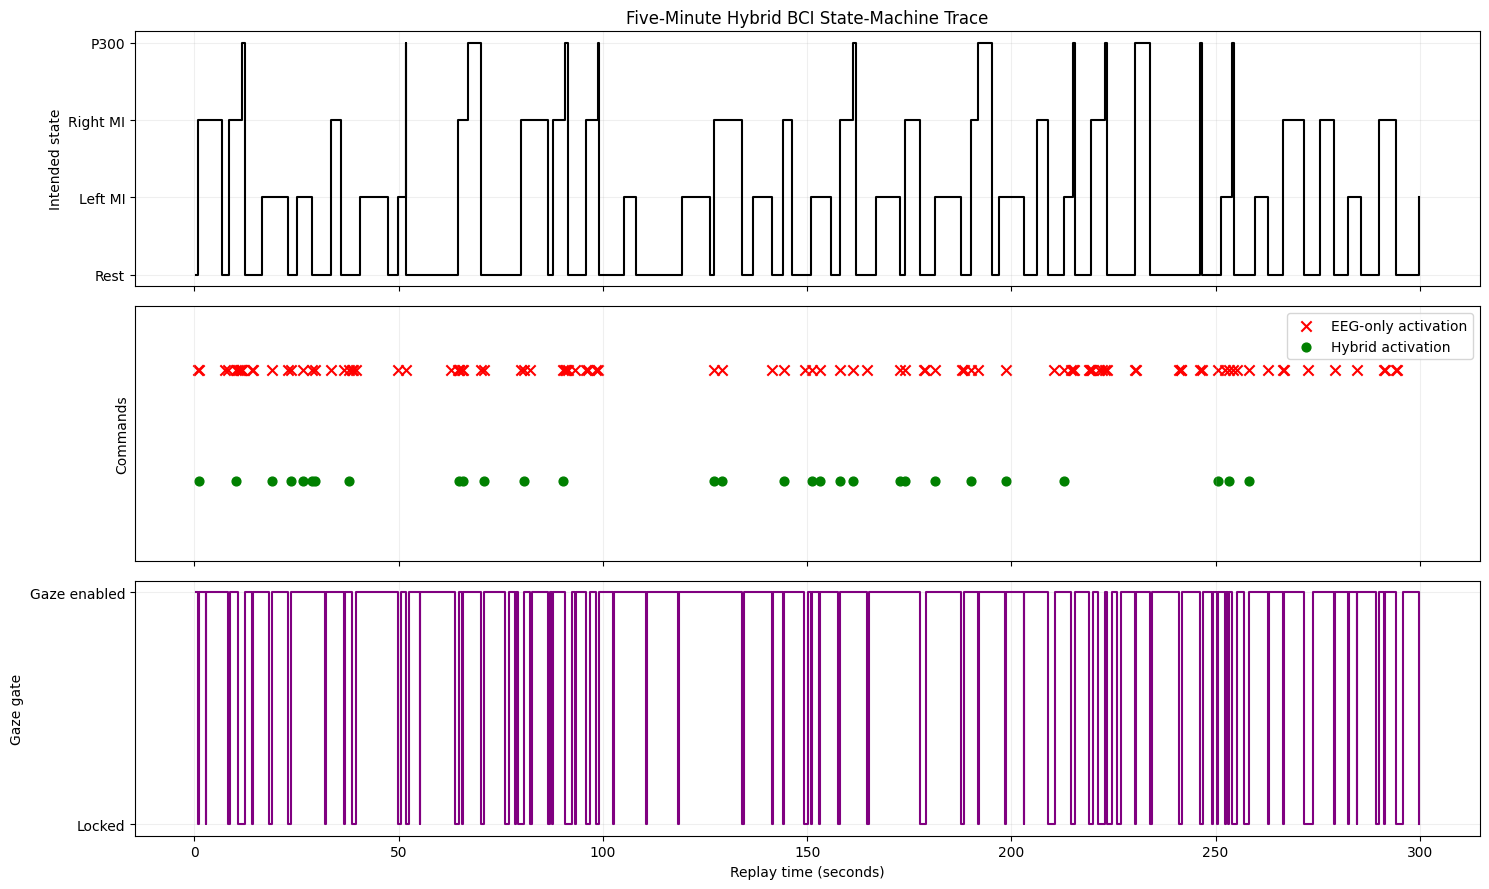

In [33]:
def eeg_only_decision(eeg_probs, confidence_thresh):
    """Choose the strongest non-rest EEG command."""
    eeg_probs = np.asarray(eeg_probs)

    command_class = int(
        np.argmax(eeg_probs[1:]) + 1
    )

    command_confidence = eeg_probs[command_class]

    if command_confidence < confidence_thresh:
        return "NO_ACTION"

    return {
        1: "MOVE_LEFT",
        2: "MOVE_RIGHT",
        3: "CLOSE_GRIPPER",
    }[command_class]


def replay_controller(confidence_thresh):
    reset_hybrid_controller()
    replay_records = []

    for row in vr_stream.itertuples():
        probabilities = np.array([
            row.probability_0,
            row.probability_1,
            row.probability_2,
            row.probability_3,
        ])

        eeg_action = eeg_only_decision(
            probabilities,
            confidence_thresh,
        )

        hybrid_result = hybrid_vr_controller(
            eeg_probs=probabilities,
            gaze_roi=int(row.gaze_roi),
            fixation_duration_ms=float(
                row.fixation_duration_ms
            ),
            confidence_thresh=confidence_thresh,
        )

        gaze_locked = (
            row.gaze_roi > 0
            and row.fixation_duration_ms >= 400
        )

        replay_records.append({
            "time_seconds": row.stream_time_seconds,
            "intended_class": row.intended_class,
            "intended_state": row.intended_state,
            "gaze_locked": gaze_locked,
            "eeg_only_action": eeg_action,
            "hybrid_state": hybrid_result["state"],
            "hybrid_action": hybrid_result["action"],
        })

    return pd.DataFrame(replay_records)


thresholds = [0.50, 0.60, 0.75]
fpar_rows = []
replay_results = {}

for threshold in thresholds:
    result_df = replay_controller(threshold)
    replay_results[threshold] = result_df

    idle_mask = result_df["intended_class"] == 0

    eeg_activation_mask = (
        result_df["eeg_only_action"] != "NO_ACTION"
    )

    hybrid_activation_mask = (
        result_df["hybrid_action"] != "NO_ACTION"
    )

    eeg_false_positives = int(
        np.sum(idle_mask & eeg_activation_mask)
    )

    hybrid_false_positives = int(
        np.sum(idle_mask & hybrid_activation_mask)
    )

    eeg_fpar = eeg_false_positives / 5
    hybrid_fpar = hybrid_false_positives / 5

    if eeg_false_positives > 0:
        reduction_percent = (
            1
            - hybrid_false_positives
            / eeg_false_positives
        ) * 100
    else:
        reduction_percent = np.nan

    fpar_rows.append({
        "Confidence threshold": threshold,
        "EEG-only activations": int(
            eeg_activation_mask.sum()
        ),
        "Hybrid activations": int(
            hybrid_activation_mask.sum()
        ),
        "EEG-only false positives": (
            eeg_false_positives
        ),
        "Hybrid false positives": (
            hybrid_false_positives
        ),
        "EEG-only FPAR/min": eeg_fpar,
        "Hybrid FPAR/min": hybrid_fpar,
        "FPAR reduction (%)": reduction_percent,
    })

fpar_table = pd.DataFrame(fpar_rows)

print("False-positive activation comparison:")
display(
    fpar_table.style.format({
        "Confidence threshold": "{:.2f}",
        "EEG-only FPAR/min": "{:.2f}",
        "Hybrid FPAR/min": "{:.2f}",
        "FPAR reduction (%)": "{:.1f}",
    })
)

# Required state-machine trace at the stress-test threshold.
plot_threshold = 0.50
trace = replay_results[plot_threshold]

eeg_activation = (
    trace["eeg_only_action"] != "NO_ACTION"
)
hybrid_activation = (
    trace["hybrid_action"] != "NO_ACTION"
)

fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 9),
    sharex=True,
)

axes[0].step(
    trace["time_seconds"],
    trace["intended_class"],
    where="post",
    color="black",
    linewidth=1.5,
)

axes[0].set_yticks(
    [0, 1, 2, 3],
    labels=[
        "Rest",
        "Left MI",
        "Right MI",
        "P300",
    ],
)
axes[0].set_ylabel("Intended state")
axes[0].set_title(
    "Five-Minute Hybrid BCI State-Machine Trace"
)
axes[0].grid(alpha=0.2)

axes[1].scatter(
    trace.loc[
        eeg_activation,
        "time_seconds",
    ],
    np.ones(eeg_activation.sum()),
    marker="x",
    s=55,
    color="red",
    label="EEG-only activation",
)

axes[1].scatter(
    trace.loc[
        hybrid_activation,
        "time_seconds",
    ],
    np.full(hybrid_activation.sum(), 0.65),
    marker="o",
    s=40,
    color="green",
    label="Hybrid activation",
)

axes[1].set_ylim(0.4, 1.2)
axes[1].set_yticks([])
axes[1].set_ylabel("Commands")
axes[1].legend(loc="upper right")
axes[1].grid(alpha=0.2)

axes[2].step(
    trace["time_seconds"],
    trace["gaze_locked"].astype(int),
    where="post",
    color="purple",
)

axes[2].set_yticks(
    [0, 1],
    labels=["Locked", "Gaze enabled"],
)
axes[2].set_ylabel("Gaze gate")
axes[2].set_xlabel("Replay time (seconds)")
axes[2].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Compute μ-ERD and shader glow intensity

Rest μ-power reference:
  C3: 1.614907e-11
  C4: 1.642571e-11

Mean C3/C4 ERD: -1.61%
Median shader glow: 0.196
Glow range: 0.000–0.613


,Trial,Mental State,C3 ERD (%),C4 ERD (%),Mean ERD (%),Shader Glow
0,1,Right-Hand MI,47.055395,52.846253,49.950824,0.499508
1,2,Right-Hand MI,65.513143,57.158268,61.335705,0.613357
2,3,Left-Hand MI,52.016962,50.889598,51.453280,0.514533
3,4,Left-Hand MI,-39.772574,-17.645629,-28.709101,0.000000
4,5,Right-Hand MI,36.765734,23.628238,30.196986,0.301970
5,6,Left-Hand MI,38.591035,42.075007,40.333021,0.403330
6,7,Left-Hand MI,44.685431,28.106137,36.395784,0.363958
7,8,Left-Hand MI,28.791223,21.236181,25.013702,0.250137
8,9,Right-Hand MI,22.788651,47.364882,35.076766,0.350768
9,10,Right-Hand MI,23.231778,43.032224,33.132001,0.331320


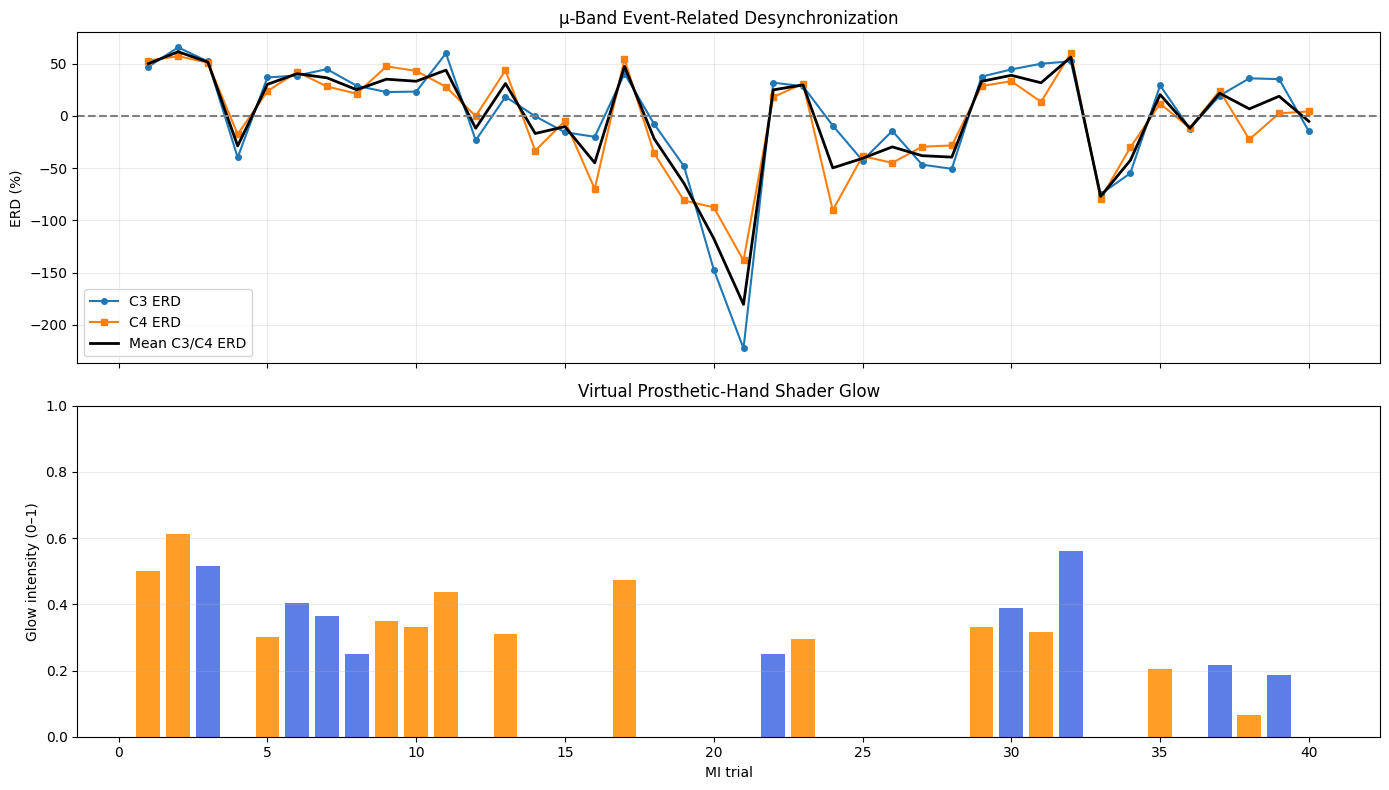


μ-ERD neurofeedback mapping completed.


In [34]:
# Reconstruct μ-band task epochs from the continuously filtered signal.
mu_task_raw = mi_filterbank_raw.copy().filter(
    l_freq=8.0,
    h_freq=12.0,
    method="fir",
    phase="zero",
    fir_design="firwin",
    verbose=False,
)

mu_task_epochs = mne.Epochs(
    mu_task_raw,
    events=filterbank_events,
    event_id=mi_event_id,
    tmin=0.5,
    tmax=3.5,
    baseline=None,
    preload=True,
    event_repeated="drop",
    verbose=False,
)

mu_rest_epochs = rest_epochs_by_band["mu_8_12"]

mu_channels = [
    channel_lookup["C3"],
    channel_lookup["C4"],
]

task_mu_data = (
    mu_task_epochs.copy()
    .pick(mu_channels)
    .get_data()
)

rest_mu_data = (
    mu_rest_epochs.copy()
    .pick(mu_channels)
    .get_data()
)

# Reference power for each channel, averaged across Rest trials and time.
rest_power_reference = np.mean(
    rest_mu_data**2,
    axis=(0, 2),
)

# Task power for each trial and channel.
task_power = np.mean(
    task_mu_data**2,
    axis=2,
)

# ERD% = ((Prest - Ptask) / Prest) × 100
erd_percent_by_channel = (
    (
        rest_power_reference[None, :]
        - task_power
    )
    / rest_power_reference[None, :]
) * 100

mean_erd_percent = np.mean(
    erd_percent_by_channel,
    axis=1,
)

# Direct linear mapping:
# 0% ERD -> glow 0.0, 100% ERD -> glow 1.0.
glow_intensity = np.clip(
    mean_erd_percent / 100,
    0.0,
    1.0,
)

erd_results = pd.DataFrame({
    "Trial": np.arange(1, len(mean_erd_percent) + 1),
    "Mental State": [
        class_names[int(label) + 1]
        for label in y_mi
    ],
    "C3 ERD (%)": erd_percent_by_channel[:, 0],
    "C4 ERD (%)": erd_percent_by_channel[:, 1],
    "Mean ERD (%)": mean_erd_percent,
    "Shader Glow": glow_intensity,
})

print("Rest μ-power reference:")
for channel, power in zip(
    mu_channels,
    rest_power_reference,
):
    print(f"  {channel}: {power:.6e}")

print(
    "\nMean C3/C4 ERD:",
    f"{mean_erd_percent.mean():.2f}%",
)
print(
    "Median shader glow:",
    f"{np.median(glow_intensity):.3f}",
)
print(
    "Glow range:",
    f"{glow_intensity.min():.3f}–"
    f"{glow_intensity.max():.3f}",
)

display(erd_results.head(10))

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 8),
    sharex=True,
)

axes[0].plot(
    erd_results["Trial"],
    erd_results["C3 ERD (%)"],
    marker="o",
    markersize=4,
    label="C3 ERD",
)

axes[0].plot(
    erd_results["Trial"],
    erd_results["C4 ERD (%)"],
    marker="s",
    markersize=4,
    label="C4 ERD",
)

axes[0].plot(
    erd_results["Trial"],
    erd_results["Mean ERD (%)"],
    color="black",
    linewidth=2,
    label="Mean C3/C4 ERD",
)

axes[0].axhline(
    0,
    color="gray",
    linestyle="--",
)

axes[0].set_title(
    "μ-Band Event-Related Desynchronization"
)
axes[0].set_ylabel("ERD (%)")
axes[0].legend()
axes[0].grid(alpha=0.25)

glow_colors = [
    "royalblue" if label == 0 else "darkorange"
    for label in y_mi
]

axes[1].bar(
    erd_results["Trial"],
    erd_results["Shader Glow"],
    color=glow_colors,
    alpha=0.85,
)

axes[1].set_title(
    "Virtual Prosthetic-Hand Shader Glow"
)
axes[1].set_xlabel("MI trial")
axes[1].set_ylabel("Glow intensity (0–1)")
axes[1].set_ylim(0, 1)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

assert np.all(
    (glow_intensity >= 0)
    & (glow_intensity <= 1)
)

print("\nμ-ERD neurofeedback mapping completed.")

### Download the real tDCS dataset

In [37]:
import json
import requests
from urllib.parse import quote

dryad_doi = "doi:10.5061/dryad.3m8j0"
encoded_doi = quote(dryad_doi, safe="")

api_headers = {
    "Accept": "application/json",
    "X-API-Version": "2.1.0",
    "User-Agent": "Mozilla/5.0",
}

dataset_url = (
    f"https://datadryad.org/api/v2/datasets/"
    f"{encoded_doi}"
)

versions_url = f"{dataset_url}/versions"

dataset_response = requests.get(
    dataset_url,
    headers=api_headers,
    timeout=60,
)

versions_response = requests.get(
    versions_url,
    headers=api_headers,
    timeout=60,
)

print("Dataset metadata status:", dataset_response.status_code)
print("Versions status:", versions_response.status_code)

if dataset_response.ok:
    print("\nDataset metadata:")
    print(
        json.dumps(
            dataset_response.json(),
            indent=2,
        )[:5000]
    )
else:
    print("\nDataset response:")
    print(dataset_response.text[:1000])

if versions_response.ok:
    print("\nVersion metadata:")
    print(
        json.dumps(
            versions_response.json(),
            indent=2,
        )[:5000]
    )
else:
    print("\nVersions response:")
    print(versions_response.text[:1000])

Dataset metadata status: 200
Versions status: 200

Dataset metadata:
{
  "_links": {
    "self": {
      "href": "/api/v2/datasets/doi%3A10.5061%2Fdryad.3m8j0"
    },
    "stash:versions": {
      "href": "/api/v2/datasets/doi%3A10.5061%2Fdryad.3m8j0/versions"
    },
    "stash:version": {
      "href": "/api/v2/versions/700"
    },
    "stash:download": {
      "href": "/api/v2/datasets/doi%3A10.5061%2Fdryad.3m8j0/download"
    },
    "curies": [
      {
        "name": "stash",
        "href": "https://github.com/datadryad/dryad-app/blob/main/documentation/apis/link_relations.md#{rel}",
        "templated": "true"
      }
    ]
  },
  "identifier": "doi:10.5061/dryad.3m8j0",
  "id": 699,
  "storageSize": 368199701,
  "relatedPublicationISSN": "1932-6203",
  "title": "Data from: Single-session tDCS over the dominant hemisphere affects contralateral spectral EEG power, but does not enhance neurofeedback-guided event-related desynchronization of the non-dominant hemisphere's sensorimoto

In [38]:
files_url = (
    "https://datadryad.org/api/v2/"
    "versions/700/files"
)

files_response = requests.get(
    files_url,
    headers=api_headers,
    timeout=60,
)

print("Files endpoint status:", files_response.status_code)

if not files_response.ok:
    print(files_response.text[:2000])
    raise RuntimeError(
        "Could not retrieve Dryad file metadata."
    )

files_metadata = files_response.json()

print(
    json.dumps(
        files_metadata,
        indent=2,
    )[:10000]
)

Files endpoint status: 200
{
  "_links": {
    "self": {
      "href": "/api/v2/versions/700/files"
    },
    "first": {
      "href": "/api/v2/versions/700/files"
    },
    "last": {
      "href": "/api/v2/versions/700/files?page=1"
    }
  },
  "count": 2,
  "total": 2,
  "_embedded": {
    "stash:files": [
      {
        "_links": {
          "self": {
            "href": "/api/v2/files/3876"
          },
          "stash:dataset": {
            "href": "/api/v2/datasets/doi%3A10.5061%2Fdryad.3m8j0"
          },
          "stash:version": {
            "href": "/api/v2/versions/700"
          },
          "stash:files": {
            "href": "/api/v2/versions/700/files"
          },
          "stash:download": {
            "href": "/api/v2/files/3876/download"
          },
          "curies": [
            {
              "name": "stash",
              "href": "https://github.com/datadryad/dryad-app/blob/main/documentation/apis/link_relations.md#{rel}",
              "templated"

### Inspect the open dataset manifest

In [40]:
tdcs_manifest_url = (
    "https://data.nemar.org/"
    "on006126/v1.0.0/manifest.json"
)

manifest_response = requests.get(
    tdcs_manifest_url,
    timeout=60,
)

manifest_response.raise_for_status()
tdcs_manifest = manifest_response.json()

print("Manifest type:", type(tdcs_manifest).__name__)
print("Manifest entries:", len(tdcs_manifest))

print("\nFirst five entries:")
print(
    json.dumps(
        tdcs_manifest[:5],
        indent=2,
    )
)

print("\nEntries containing Anodal or Sham sessions:")

anodal_sham_entries = [
    entry
    for entry in tdcs_manifest
    if (
        "ses-An" in json.dumps(entry)
        or "ses-Sh" in json.dumps(entry)
    )
]

print(
    "Anodal/Sham entries:",
    len(anodal_sham_entries),
)

print(
    json.dumps(
        anodal_sham_entries[:10],
        indent=2,
    )
)

Manifest type: list
Manifest entries: 656

First five entries:
[
  {
    "path": ".bidsignore",
    "size": 15,
    "checksum_algorithm": "git",
    "checksum": "8a18cb5aa91838ee13dc8e760de95b98be8741aa",
    "bytes_url": "https://data.nemar.org/on006126/v1.0.0/.bidsignore",
    "url": "https://data.nemar.org/on006126/v1.0.0/.bidsignore"
  },
  {
    "path": ".datalad/config",
    "size": 63,
    "checksum_algorithm": "git",
    "checksum": "7bf66d940814aa67cc494d7032f7ee0a83f84856",
    "bytes_url": "https://data.nemar.org/on006126/v1.0.0/.datalad/config",
    "url": "https://data.nemar.org/on006126/v1.0.0/.datalad/config"
  },
  {
    "path": ".gitattributes",
    "size": 427,
    "checksum_algorithm": "git",
    "checksum": "a8599a8e5fdb959624a4c8684c1aa55fb69f5522",
    "bytes_url": "https://data.nemar.org/on006126/v1.0.0/.gitattributes",
    "url": "https://data.nemar.org/on006126/v1.0.0/.gitattributes"
  },
  {
    "path": ".nemar/metadata.json",
    "size": 550,
    "checksum_al

### Inspect task definitions and event labels

In [41]:
import io
import re


def manifest_entry(path):
    matches = [
        entry
        for entry in tdcs_manifest
        if entry["path"] == path
    ]

    if not matches:
        raise KeyError(
            f"Manifest path not found: {path}"
        )

    return matches[0]


def fetch_manifest_text(path):
    entry = manifest_entry(path)

    response = requests.get(
        entry["bytes_url"],
        timeout=60,
    )
    response.raise_for_status()

    return response.text


# Read the dataset-level documentation.
readme_text = fetch_manifest_text("README.md")

print("DATASET README")
print("=" * 70)
print(readme_text[:10000])

# Inspect participant and session metadata.
participants_text = fetch_manifest_text(
    "participants.tsv"
)

sessions_text = fetch_manifest_text(
    "sessions.tsv"
)

print("\nPARTICIPANTS")
display(
    pd.read_csv(
        io.StringIO(participants_text),
        sep="\t",
    )
)

print("\nSESSIONS")
display(
    pd.read_csv(
        io.StringIO(sessions_text),
        sep="\t",
    )
)

# Find one Anodal event table for each task.
event_entries = [
    entry
    for entry in tdcs_manifest
    if (
        entry["path"].startswith(
            "sub-AnSt01/ses-An/"
        )
        and entry["path"].endswith(
            "_events.tsv"
        )
    )
]

task_to_entry = {}

for entry in event_entries:
    match = re.search(
        r"_task-([^_]+)_",
        entry["path"],
    )

    if match:
        task_name = match.group(1)
        task_to_entry.setdefault(
            task_name,
            entry,
        )

print(
    "\nTasks found:",
    sorted(task_to_entry),
)

for task_name in sorted(task_to_entry):
    entry = task_to_entry[task_name]

    response = requests.get(
        entry["bytes_url"],
        timeout=60,
    )
    response.raise_for_status()

    events_table = pd.read_csv(
        io.StringIO(response.text),
        sep="\t",
    )

    print("\n" + "=" * 70)
    print("Task:", task_name)
    print("Path:", entry["path"])
    print("Columns:", list(events_table.columns))

    if "trial_type" in events_table.columns:
        print("Trial-type counts:")
        print(
            events_table["trial_type"]
            .value_counts(dropna=False)
        )

    display(events_table.head(10))

DATASET README
[![DOI](https://img.shields.io/badge/DOI-10.82901%2Fnemar.on006126-blue)](https://doi.org/10.82901/nemar.on006126)

# TDCS Neuromodulated Motor Imagery TMS Dataset

## Research/Experiment Description

[Your research description goes here]

## BIDS Report

 The TDCS Modulation of Visual Cortex in Motor Imagery dataset was created by
Anthony Mensah, Gleb Perevoznyuk, Artyom Batov, and Aleksandra S. Pleskovskaya
and conforms to BIDS version 1.7.0. This report was generated with MNE-BIDS
(https://doi.org/10.21105/joss.01896). The dataset consists of 5 participants
(comprised of 3 male and 3 female participants; comprised of 6 right hand, 0
left hand and 0 ambidextrous; ages ranged from 18.0 to 30.0 (mean = 23.0, std =
5.1)) and 3 recording sessions: An, Ca, and Sh. Data was recorded using an EEG
system (Brain Products) sampled at 5000.0 Hz with line noise at 60.0 Hz. There
were 90 scans in total. Recording durations ranged from 363.7 to 2910.98 seconds
(mean = 429.21, std = 

,participant_id,age,sex,hand
0,sub-AnSt01,22,F,R
1,sub-FeKl03,19,M,R
2,sub-IrCh04,30,M,R
3,sub-KiKo09,19,F,R
4,sub-SoNi11,30,M,R
5,sub-AlBy15,18,F,R



SESSIONS


,session_id,session_name,intensity,duration,positive_electrode,negative_electrode,protocol
0,An,Anodal,1mA,21,V1,Left Clavicle,9-3-9
1,Ca,Cathodal,-1mA,21,Left Clavicle,V1,9-3-9
2,Sh,Sham,0mA,21,V1,Left Clavicle,9-3-9



Tasks found: ['B1', 'B2', 'BM', 'KI', 'V1', 'V3']

Task: B1
Path: sub-AnSt01/ses-An/eeg/sub-AnSt01_ses-An_task-B1_run-01_events.tsv
Columns: ['onset', 'duration', 'trial_type', 'value', 'sample', 'tms rmt', 'working amplitude']
Trial-type counts:
trial_type
Stimulus/S128    59
New Segment/      1
Name: count, dtype: int64


,onset,duration,trial_type,value,sample,tms rmt,working amplitude
0,0.0000,0.0002,New Segment/,1,0,63.0,70.0
1,67.4712,0.0002,Stimulus/S128,2,337356,63.0,70.0
2,73.3048,0.0002,Stimulus/S128,2,366524,63.0,70.0
3,79.1390,0.0002,Stimulus/S128,2,395695,63.0,70.0
4,84.9732,0.0002,Stimulus/S128,2,424866,63.0,70.0
5,146.1062,0.0002,Stimulus/S128,2,730531,63.0,70.0
6,176.4504,0.0002,Stimulus/S128,2,882252,63.0,70.0
7,183.2846,0.0002,Stimulus/S128,2,916423,63.0,70.0
8,191.1188,0.0002,Stimulus/S128,2,955594,63.0,70.0
9,197.9532,0.0002,Stimulus/S128,2,989766,63.0,70.0


... (6 outputs left out)


Task: V1
Path: sub-AnSt01/ses-An/eeg/sub-AnSt01_ses-An_task-V1_run-03_events.tsv
Columns: ['onset', 'duration', 'trial_type', 'value', 'sample', 'tms rmt', 'working amplitude']
Trial-type counts:
trial_type
Stimulus/S128    54
New Segment/      1
Name: count, dtype: int64


,onset,duration,trial_type,value,sample,tms rmt,working amplitude
0,0.0000,0.0002,New Segment/,1,0,63.0,70.0
1,26.7602,0.0002,Stimulus/S128,2,133801,63.0,70.0
2,33.8374,0.0002,Stimulus/S128,2,169187,63.0,70.0
3,40.9356,0.0002,Stimulus/S128,2,204678,63.0,70.0
4,49.0060,0.0002,Stimulus/S128,2,245030,63.0,70.0
5,56.0902,0.0002,Stimulus/S128,2,280451,63.0,70.0
6,62.1606,0.0002,Stimulus/S128,2,310803,63.0,70.0
7,68.2238,0.0002,Stimulus/S128,2,341119,63.0,70.0
8,74.2940,0.0002,Stimulus/S128,2,371470,63.0,70.0
9,81.3644,0.0002,Stimulus/S128,2,406822,63.0,70.0



Task: V3
Path: sub-AnSt01/ses-An/eeg/sub-AnSt01_ses-An_task-V3_run-05_events.tsv
Columns: ['onset', 'duration', 'trial_type', 'value', 'sample', 'tms rmt', 'working amplitude']
Trial-type counts:
trial_type
Stimulus/S128    54
New Segment/      1
Name: count, dtype: int64


,onset,duration,trial_type,value,sample,tms rmt,working amplitude
0,0.0000,0.0002,New Segment/,1,0,63.0,70.0
1,11.6170,0.0002,Stimulus/S128,2,58085,63.0,70.0
2,19.6804,0.0002,Stimulus/S128,2,98402,63.0,70.0
3,25.7506,0.0002,Stimulus/S128,2,128753,63.0,70.0
4,33.8140,0.0002,Stimulus/S128,2,169070,63.0,70.0
5,41.8776,0.0002,Stimulus/S128,2,209388,63.0,70.0
6,47.9410,0.0002,Stimulus/S128,2,239705,63.0,70.0
7,56.0044,0.0002,Stimulus/S128,2,280022,63.0,70.0
8,63.0748,0.0002,Stimulus/S128,2,315374,63.0,70.0
9,71.1452,0.0002,Stimulus/S128,2,355726,63.0,70.0


### Select only the required Anodal/Sham EEG files

In [42]:
selected_tdcs_sessions = {"An", "Sh"}
selected_tdcs_tasks = {"BM", "KI", "V1", "V3"}
required_signal_suffixes = (
    "_eeg.eeg",
    "_eeg.vhdr",
    "_eeg.vmrk",
)

selected_tdcs_entries = []

for entry in tdcs_manifest:
    path = entry["path"]

    subject_match = re.search(
        r"(sub-[^/]+)/",
        path,
    )

    session_match = re.search(
        r"/ses-([^/]+)/",
        path,
    )

    task_match = re.search(
        r"_task-([^_]+)_",
        path,
    )

    if not (
        subject_match
        and session_match
        and task_match
    ):
        continue

    subject_id = subject_match.group(1)
    session_id = session_match.group(1)
    task_id = task_match.group(1)

    if (
        session_id in selected_tdcs_sessions
        and task_id in selected_tdcs_tasks
        and path.endswith(required_signal_suffixes)
    ):
        selected_tdcs_entries.append({
            **entry,
            "subject": subject_id,
            "session": session_id,
            "task": task_id,
        })

selected_tdcs_table = pd.DataFrame(
    selected_tdcs_entries
)

total_download_mb = (
    selected_tdcs_table["size"].sum()
    / (1024**2)
)

print(
    "Participants:",
    sorted(
        selected_tdcs_table["subject"].unique()
    ),
)

print(
    "Sessions:",
    sorted(
        selected_tdcs_table["session"].unique()
    ),
)

print(
    "Tasks:",
    sorted(
        selected_tdcs_table["task"].unique()
    ),
)

print(
    "Selected files:",
    len(selected_tdcs_table),
)

print(
    "Estimated download size:",
    f"{total_download_mb:.2f} MB",
)

file_count_check = (
    selected_tdcs_table
    .groupby(
        ["subject", "session", "task"]
    )
    .size()
    .rename("file_count")
    .reset_index()
)

print("\nFiles per subject/session/task:")
display(file_count_check)

unexpected_counts = file_count_check[
    file_count_check["file_count"] != 3
]

if len(unexpected_counts):
    print(
        "\nWarning: some recordings do not have "
        "all three BrainVision files:"
    )
    display(unexpected_counts)
else:
    print(
        "\nEvery selected recording has the required "
        ".eeg, .vhdr, and .vmrk triplet."
    )

Participants: ['sub-AnSt01', 'sub-FeKl03', 'sub-IrCh04', 'sub-KiKo09', 'sub-SoNi11']
Sessions: ['An', 'Sh']
Tasks: ['BM', 'KI', 'V1', 'V3']
Selected files: 120
Estimated download size: 454.19 MB

Files per subject/session/task:


,subject,session,task,file_count
0,sub-AnSt01,An,BM,3
1,sub-AnSt01,An,KI,3
2,sub-AnSt01,An,V1,3
3,sub-AnSt01,An,V3,3
4,sub-AnSt01,Sh,BM,3
5,sub-AnSt01,Sh,KI,3
6,sub-AnSt01,Sh,V1,3
7,sub-AnSt01,Sh,V3,3
8,sub-FeKl03,An,BM,3
9,sub-FeKl03,An,KI,3



Every selected recording has the required .eeg, .vhdr, and .vmrk triplet.


### Download and verify the selected tDCS recordings

In [43]:
from pathlib import Path
import hashlib

tdcs_data_root = Path(
    "/content/tdcs_mi_dataset"
)

tdcs_data_root.mkdir(
    parents=True,
    exist_ok=True,
)

total_expected_bytes = int(
    selected_tdcs_table["size"].sum()
)

download_session = requests.Session()
download_session.headers.update({
    "User-Agent": "Mozilla/5.0",
})

downloaded_files = []
skipped_files = []

with tqdm(
    total=total_expected_bytes,
    unit="B",
    unit_scale=True,
    desc="Downloading tDCS data",
) as overall_progress:

    for entry in selected_tdcs_entries:
        relative_path = Path(entry["path"])
        output_path = tdcs_data_root / relative_path
        expected_size = int(entry["size"])
        expected_checksum = entry["checksum"]
        checksum_algorithm = entry[
            "checksum_algorithm"
        ]

        output_path.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        # Reuse a previously verified-size file.
        if (
            output_path.exists()
            and output_path.stat().st_size
            == expected_size
        ):
            overall_progress.update(expected_size)
            skipped_files.append(output_path)
            continue

        hash_object = hashlib.new(
            checksum_algorithm
        )

        with download_session.get(
            entry["bytes_url"],
            stream=True,
            allow_redirects=True,
            timeout=180,
        ) as response:
            response.raise_for_status()

            with open(output_path, "wb") as file_handle:
                for chunk in response.iter_content(
                    chunk_size=1024 * 1024
                ):
                    if chunk:
                        file_handle.write(chunk)
                        hash_object.update(chunk)
                        overall_progress.update(len(chunk))

        actual_size = output_path.stat().st_size
        actual_checksum = hash_object.hexdigest()

        if actual_size != expected_size:
            raise RuntimeError(
                f"Size mismatch: {relative_path}"
            )

        if (
            actual_checksum.lower()
            != expected_checksum.lower()
        ):
            raise RuntimeError(
                f"Checksum mismatch: {relative_path}"
            )

        downloaded_files.append(output_path)

all_local_signal_files = list(
    tdcs_data_root.rglob("*_eeg.*")
)

actual_total_mb = sum(
    path.stat().st_size
    for path in all_local_signal_files
) / (1024**2)

print("\nNewly downloaded files:", len(downloaded_files))
print("Previously present files:", len(skipped_files))
print("Local signal files:", len(all_local_signal_files))
print(
    "Local signal-data size:",
    f"{actual_total_mb:.2f} MB",
)

print("\nExample downloaded files:")
for path in all_local_signal_files[:10]:
    print(" -", path.relative_to(tdcs_data_root))

assert len(all_local_signal_files) == 120

print("\nAll selected tDCS recordings downloaded and verified.")


Newly downloaded files: 120
Previously present files: 0
Local signal files: 120
Local signal-data size: 454.19 MB

Example downloaded files:
 - sub-KiKo09/ses-Sh/eeg/sub-KiKo09_ses-Sh_task-V3_run-02_eeg.vhdr
 - sub-KiKo09/ses-Sh/eeg/sub-KiKo09_ses-Sh_task-KI_run-03_eeg.vmrk
 - sub-KiKo09/ses-Sh/eeg/sub-KiKo09_ses-Sh_task-KI_run-03_eeg.vhdr
 - sub-KiKo09/ses-Sh/eeg/sub-KiKo09_ses-Sh_task-BM_run-05_eeg.vhdr
 - sub-KiKo09/ses-Sh/eeg/sub-KiKo09_ses-Sh_task-V1_run-04_eeg.eeg
 - sub-KiKo09/ses-Sh/eeg/sub-KiKo09_ses-Sh_task-V3_run-02_eeg.eeg
 - sub-KiKo09/ses-Sh/eeg/sub-KiKo09_ses-Sh_task-V3_run-02_eeg.vmrk
 - sub-KiKo09/ses-Sh/eeg/sub-KiKo09_ses-Sh_task-V1_run-04_eeg.vmrk
 - sub-KiKo09/ses-Sh/eeg/sub-KiKo09_ses-Sh_task-BM_run-05_eeg.vmrk
 - sub-KiKo09/ses-Sh/eeg/sub-KiKo09_ses-Sh_task-V1_run-04_eeg.vhdr

All selected tDCS recordings downloaded and verified.


### Inspect one tDCS recording

In [44]:
example_vhdr = sorted(
    tdcs_data_root.rglob("*_eeg.vhdr")
)[0]

example_tdcs_raw = mne.io.read_raw_brainvision(
    example_vhdr,
    preload=False,
    verbose=False,
)

print("Example file:")
print(example_vhdr.relative_to(tdcs_data_root))

print("\nRecording information:")
print(
    "Sampling frequency:",
    example_tdcs_raw.info["sfreq"],
    "Hz",
)
print(
    "Duration:",
    f"{example_tdcs_raw.times[-1]:.2f} seconds",
)
print(
    "Channel names:",
    example_tdcs_raw.ch_names,
)
print(
    "Channel types:",
    example_tdcs_raw.get_channel_types(),
)

print("\nAnnotations:")
print(
    "Number of annotations:",
    len(example_tdcs_raw.annotations),
)
print(
    "Annotation labels:",
    sorted(
        set(
            example_tdcs_raw.annotations.description
        )
    ),
)

print("\nFirst ten annotations:")
for index in range(
    min(10, len(example_tdcs_raw.annotations))
):
    print(
        f"{index}: "
        f"onset={example_tdcs_raw.annotations.onset[index]:.4f}, "
        f"duration={example_tdcs_raw.annotations.duration[index]:.4f}, "
        f"description="
        f"{example_tdcs_raw.annotations.description[index]}"
    )

print("\nChannel metadata:")
for channel_index, channel_name in enumerate(
    example_tdcs_raw.ch_names
):
    print(
        channel_name,
        "unit:",
        example_tdcs_raw._orig_units.get(
            channel_name,
            "unknown",
        ),
    )

Example file:
sub-AnSt01/ses-An/eeg/sub-AnSt01_ses-An_task-BM_run-04_eeg.vhdr

Recording information:
Sampling frequency: 5000.0 Hz
Duration: 398.38 seconds
Channel names: ['FDI_R', 'ADM_R', 'APB_R']
Channel types: ['eeg', 'eeg', 'eeg']

Annotations:
Number of annotations: 54
Annotation labels: ['Stimulus/S128']

First ten annotations:
0: onset=17.4574, duration=0.0002, description=Stimulus/S128
1: onset=24.5346, duration=0.0002, description=Stimulus/S128
2: onset=32.6120, duration=0.0002, description=Stimulus/S128
3: onset=40.6826, duration=0.0002, description=Stimulus/S128
4: onset=46.7598, duration=0.0002, description=Stimulus/S128
5: onset=52.8230, duration=0.0002, description=Stimulus/S128
6: onset=59.9004, duration=0.0002, description=Stimulus/S128
7: onset=65.9706, duration=0.0002, description=Stimulus/S128
8: onset=74.0410, duration=0.0002, description=Stimulus/S128
9: onset=81.1044, duration=0.0002, description=Stimulus/S128

Channel metadata:
FDI_R unit: µV
ADM_R unit: µV
APB

### Create the paired clinical-performance table and calculate ITR

In [45]:
from scipy.stats import (
    wilcoxon,
    ttest_rel,
)

# Subject-level values transcribed from the published Table 1.
# Pseudo-stimulation is used as the Sham condition.
tdcs_results = pd.DataFrame({
    "Subject": np.arange(1, 16),
    "Sham Accuracy (%)": [
        93.21, 85.84, 76.25, 85.00, 85.00,
        78.64, 71.25, 77.50, 91.28, 92.50,
        92.78, 80.20, 87.34, 82.06, 87.98,
    ],
    "Anodal Accuracy (%)": [
        96.88, 97.50, 80.00, 90.06, 86.25,
        82.68, 87.49, 81.27, 96.31, 97.50,
        92.70, 95.00, 90.00, 85.00, 90.28,
    ],
})

# The source reports balanced MI classification accuracy but not
# class-wise confusion matrices. Accuracy is therefore retained as
# an explicitly labelled Macro-F1 proxy.
tdcs_results["Sham Macro F1 Proxy"] = (
    tdcs_results["Sham Accuracy (%)"] / 100
)

tdcs_results["Anodal Macro F1 Proxy"] = (
    tdcs_results["Anodal Accuracy (%)"] / 100
)


def wolpaw_itr(
    accuracy,
    n_classes=4,
    decision_window_seconds=3.0,
):
    """
    Wolpaw ITR using the assignment's N=4 classes and
    the 3-second MI decision window.
    """
    probability = np.asarray(
        accuracy,
        dtype=float,
    )

    probability = np.clip(
        probability,
        1e-12,
        1 - 1e-12,
    )

    bits_per_decision = (
        np.log2(n_classes)
        + probability * np.log2(probability)
        + (1 - probability)
        * np.log2(
            (1 - probability)
            / (n_classes - 1)
        )
    )

    bits_per_decision = np.maximum(
        bits_per_decision,
        0,
    )

    return (
        bits_per_decision
        * 60
        / decision_window_seconds
    )


tdcs_results["Sham ITR (bits/min)"] = wolpaw_itr(
    tdcs_results["Sham Macro F1 Proxy"]
)

tdcs_results["Anodal ITR (bits/min)"] = wolpaw_itr(
    tdcs_results["Anodal Macro F1 Proxy"]
)

tdcs_results["F1 Proxy Gain"] = (
    tdcs_results["Anodal Macro F1 Proxy"]
    - tdcs_results["Sham Macro F1 Proxy"]
)

tdcs_results["ITR Gain (bits/min)"] = (
    tdcs_results["Anodal ITR (bits/min)"]
    - tdcs_results["Sham ITR (bits/min)"]
)

print("Paired tDCS performance table:")
display(
    tdcs_results.style.format({
        "Sham Accuracy (%)": "{:.2f}",
        "Anodal Accuracy (%)": "{:.2f}",
        "Sham Macro F1 Proxy": "{:.3f}",
        "Anodal Macro F1 Proxy": "{:.3f}",
        "Sham ITR (bits/min)": "{:.2f}",
        "Anodal ITR (bits/min)": "{:.2f}",
        "F1 Proxy Gain": "{:+.3f}",
        "ITR Gain (bits/min)": "{:+.2f}",
    })
)

print("\nGroup means:")
print(
    "Sham Macro F1 proxy:",
    f"{tdcs_results['Sham Macro F1 Proxy'].mean():.3f}",
)
print(
    "Anodal Macro F1 proxy:",
    f"{tdcs_results['Anodal Macro F1 Proxy'].mean():.3f}",
)
print(
    "Sham ITR:",
    f"{tdcs_results['Sham ITR (bits/min)'].mean():.2f} bits/min",
)
print(
    "Anodal ITR:",
    f"{tdcs_results['Anodal ITR (bits/min)'].mean():.2f} bits/min",
)
print(
    "Mean ITR gain:",
    f"{tdcs_results['ITR Gain (bits/min)'].mean():.2f} bits/min",
)

Paired tDCS performance table:


,Subject,Sham Accuracy (%),Anodal Accuracy (%),Sham Macro F1 Proxy,Anodal Macro F1 Proxy,Sham ITR (bits/min),Anodal ITR (bits/min),F1 Proxy Gain,ITR Gain (bits/min)
0,1,93.21,96.88,0.932,0.969,30.69,35.00,+0.037,+4.32
1,2,85.84,97.50,0.858,0.975,23.74,35.83,+0.117,+12.09
2,3,76.25,80.00,0.762,0.800,16.65,19.22,+0.038,+2.57
3,4,85.00,90.06,0.850,0.901,23.05,27.51,+0.051,+4.46
4,5,85.00,86.25,0.850,0.863,23.05,24.09,+0.013,+1.04
5,6,78.64,82.68,0.786,0.827,18.26,21.21,+0.040,+2.95
6,7,71.25,87.49,0.713,0.875,13.58,25.16,+0.162,+11.58
7,8,77.50,81.27,0.775,0.813,17.48,20.15,+0.038,+2.66
8,9,91.28,96.31,0.913,0.963,28.69,34.27,+0.050,+5.58
9,10,92.50,97.50,0.925,0.975,29.94,35.83,+0.050,+5.90



Group means:
Sham Macro F1 proxy: 0.845
Anodal Macro F1 proxy: 0.899
Sham ITR: 23.07 bits/min
Anodal ITR: 27.96 bits/min
Mean ITR gain: 4.88 bits/min


### Paired statistical tests and summary figure

Paired statistical summary:


,Outcome,Sham mean,Anodal mean,Mean gain,Wilcoxon statistic,Wilcoxon p-value,Paired t statistic,Paired t p-value,Paired Cohen d
0,Macro F1 proxy,0.845,0.899,+0.055,1.000,0.000122,4.392,0.000614,1.134
1,ITR (bits/min),23.072,27.955,+4.883,1.000,0.000122,4.532,0.000470,1.170


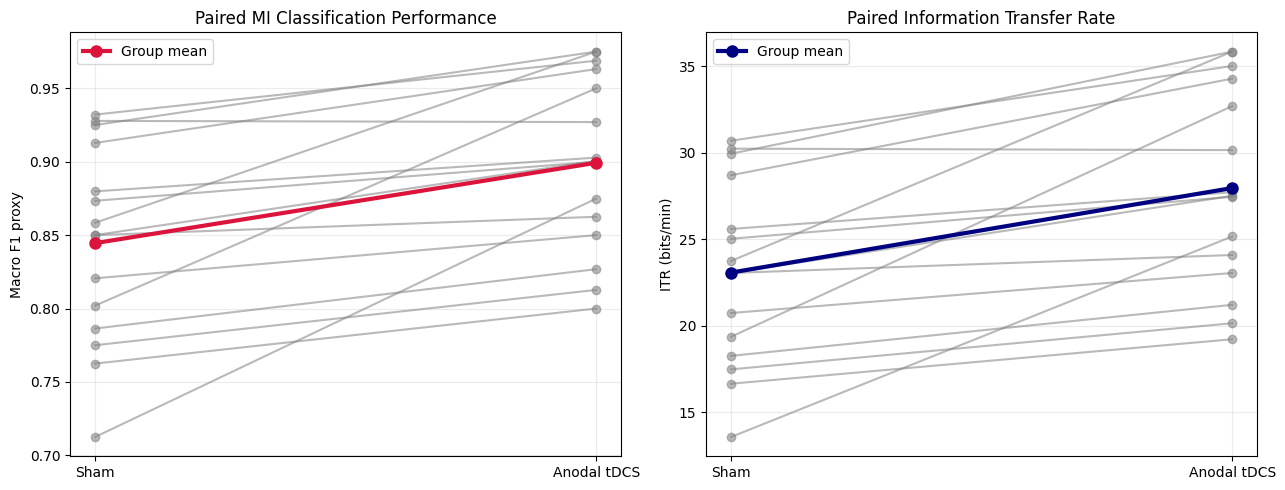


Primary result — Macro F1 proxy: W=1.000, p=0.000122
Primary result — ITR: W=1.000, p=0.000122, mean gain=4.88 bits/min


In [46]:
sham_f1 = tdcs_results[
    "Sham Macro F1 Proxy"
].to_numpy()

anodal_f1 = tdcs_results[
    "Anodal Macro F1 Proxy"
].to_numpy()

sham_itr = tdcs_results[
    "Sham ITR (bits/min)"
].to_numpy()

anodal_itr = tdcs_results[
    "Anodal ITR (bits/min)"
].to_numpy()

# Primary non-parametric paired tests.
f1_wilcoxon = wilcoxon(
    anodal_f1,
    sham_f1,
    alternative="two-sided",
)

itr_wilcoxon = wilcoxon(
    anodal_itr,
    sham_itr,
    alternative="two-sided",
)

# Supporting paired t-tests.
f1_ttest = ttest_rel(
    anodal_f1,
    sham_f1,
)

itr_ttest = ttest_rel(
    anodal_itr,
    sham_itr,
)


def paired_cohens_d(
    condition_a,
    condition_b,
):
    differences = (
        np.asarray(condition_a)
        - np.asarray(condition_b)
    )

    return (
        differences.mean()
        / differences.std(ddof=1)
    )


f1_effect_size = paired_cohens_d(
    anodal_f1,
    sham_f1,
)

itr_effect_size = paired_cohens_d(
    anodal_itr,
    sham_itr,
)

statistical_summary = pd.DataFrame([
    {
        "Outcome": "Macro F1 proxy",
        "Sham mean": sham_f1.mean(),
        "Anodal mean": anodal_f1.mean(),
        "Mean gain": (
            anodal_f1 - sham_f1
        ).mean(),
        "Wilcoxon statistic": (
            f1_wilcoxon.statistic
        ),
        "Wilcoxon p-value": (
            f1_wilcoxon.pvalue
        ),
        "Paired t statistic": (
            f1_ttest.statistic
        ),
        "Paired t p-value": (
            f1_ttest.pvalue
        ),
        "Paired Cohen d": f1_effect_size,
    },
    {
        "Outcome": "ITR (bits/min)",
        "Sham mean": sham_itr.mean(),
        "Anodal mean": anodal_itr.mean(),
        "Mean gain": (
            anodal_itr - sham_itr
        ).mean(),
        "Wilcoxon statistic": (
            itr_wilcoxon.statistic
        ),
        "Wilcoxon p-value": (
            itr_wilcoxon.pvalue
        ),
        "Paired t statistic": (
            itr_ttest.statistic
        ),
        "Paired t p-value": (
            itr_ttest.pvalue
        ),
        "Paired Cohen d": itr_effect_size,
    },
])

print("Paired statistical summary:")
display(
    statistical_summary.style.format({
        "Sham mean": "{:.3f}",
        "Anodal mean": "{:.3f}",
        "Mean gain": "{:+.3f}",
        "Wilcoxon statistic": "{:.3f}",
        "Wilcoxon p-value": "{:.6f}",
        "Paired t statistic": "{:.3f}",
        "Paired t p-value": "{:.6f}",
        "Paired Cohen d": "{:.3f}",
    })
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)

for subject_index in range(len(tdcs_results)):
    axes[0].plot(
        [0, 1],
        [
            sham_f1[subject_index],
            anodal_f1[subject_index],
        ],
        color="gray",
        alpha=0.55,
        marker="o",
    )

axes[0].plot(
    [0, 1],
    [sham_f1.mean(), anodal_f1.mean()],
    color="crimson",
    linewidth=3,
    marker="o",
    markersize=8,
    label="Group mean",
)

axes[0].set_xticks(
    [0, 1],
    labels=["Sham", "Anodal tDCS"],
)
axes[0].set_ylabel("Macro F1 proxy")
axes[0].set_title(
    "Paired MI Classification Performance"
)
axes[0].legend()
axes[0].grid(alpha=0.25)

for subject_index in range(len(tdcs_results)):
    axes[1].plot(
        [0, 1],
        [
            sham_itr[subject_index],
            anodal_itr[subject_index],
        ],
        color="gray",
        alpha=0.55,
        marker="o",
    )

axes[1].plot(
    [0, 1],
    [sham_itr.mean(), anodal_itr.mean()],
    color="navy",
    linewidth=3,
    marker="o",
    markersize=8,
    label="Group mean",
)

axes[1].set_xticks(
    [0, 1],
    labels=["Sham", "Anodal tDCS"],
)
axes[1].set_ylabel("ITR (bits/min)")
axes[1].set_title(
    "Paired Information Transfer Rate"
)
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print(
    "\nPrimary result — Macro F1 proxy:",
    f"W={f1_wilcoxon.statistic:.3f},",
    f"p={f1_wilcoxon.pvalue:.6f}",
)

print(
    "Primary result — ITR:",
    f"W={itr_wilcoxon.statistic:.3f},",
    f"p={itr_wilcoxon.pvalue:.6f},",
    f"mean gain="
    f"{(anodal_itr - sham_itr).mean():.2f} bits/min",
)

## Asynchronous Hybrid P300–MI Speller for Complete Locked-In State

### Proposed architecture

The system operates asynchronously, allowing the user to initiate communication without an externally imposed trial schedule.

1. **Idle state:**  
   The interface remains inactive while continuously monitoring EEG. An explicit idle/rest model prevents ordinary background EEG from producing commands.

2. **MI-based brain switch:**  
   Sustained left- or right-hand motor imagery activates the spelling interface. A command is accepted only when the MI classifier exceeds its confidence threshold for multiple consecutive windows.

3. **Gaze-independent P300 selection:**  
   After activation, characters are presented using an auditory, tactile, or centrally located visual oddball paradigm. The user attends to the desired character, producing a P300 response without requiring reliable eye movement or peripheral visual fixation.

4. **P300 confirmation:**  
   Evidence is accumulated across several stimulus repetitions. A character is selected only when the target probability crosses a predefined confidence threshold.

5. **MI confirmation or cancellation:**  
   A second MI command confirms the selected character. Rest, timeout, or an alternative MI command cancels the selection and returns the system to the idle state.

### False-alarm suppression

False activations would be reduced through:

- A dedicated idle-state classifier.
- Consecutive-window MI confirmation rather than a single-window decision.
- Temporal probability smoothing and evidence accumulation.
- Separate activation and deactivation thresholds to provide hysteresis.
- Multiple P300 repetitions before character selection.
- A refractory interval after every accepted command.
- Artifact rejection for excessive EEG amplitude, muscle activity, or electrode noise.
- Automatic cancellation when classifier confidence decreases or no confirmation arrives.
- Subject-specific calibration and adaptive confidence thresholds.

### State sequence

`IDLE → MI_ACTIVATION → SPELLER_ACTIVE → P300_SELECTION → MI_CONFIRMATION → OUTPUT`

Any low-confidence, contradictory, or timed-out decision returns the controller to `IDLE`.

### Clinical considerations

An auditory or tactile P300 interface may be preferable for users with impaired gaze control or unreliable vision. Calibration should be short, fatigue-aware, and repeatedly updated because attention, medication, electrode impedance, and disease progression can change EEG responses over time.

The current experiment demonstrates the computational architecture using healthy-participant public data. Clinical performance in complete locked-in state would require prospective validation and must not be inferred directly from these results.

## Final Results and Critical Discussion

### 1. Signal Processing and Feature Engineering

Motor-imagery EEG was resampled to 250 Hz, filtered from 8–30 Hz, and segmented from 0.5–3.5 s after each cue. ICA-based ocular-artifact inspection found no components requiring removal. Five frequency-specific CSP banks produced 30 features per trial. P300 EEG was filtered from 0.5–15 Hz, baseline-corrected over −0.2–0 s, and epoched from −0.2–0.8 s. Temporal ERP samples from Pz, P3, P4, POz, and Oz supplied 125 features.

The combined representation contained 155 features. PCA retained 31 components and 95.20% of the variance, whereas mutual-information selection retained the 20 most discriminative original features. The strongest features were predominantly μ- and β-band CSP components, supporting the importance of sensorimotor rhythm modulation.

### 2. Four-Class Classification

The balanced dataset contained 80 observations across Rest/Idle, Left-Hand MI, Right-Hand MI, and P300 Target classes. Five-fold out-of-fold evaluation produced:

| Model | Accuracy | Macro Precision | Macro Recall | Macro F1 |
|---|---:|---:|---:|---:|
| LDA | 0.588 | 0.577 | 0.587 | 0.575 |
| SVM (RBF) | 0.575 | 0.579 | 0.575 | **0.576** |
| k-NN | 0.562 | 0.603 | 0.562 | 0.531 |
| EEGNet | 0.225 | 0.228 | 0.225 | 0.222 |

The RBF SVM achieved the highest Macro F1 and was selected for the controller. Its largest error was bidirectional confusion between Rest/Idle and Left-Hand MI, with a mean cross-confusion rate of 0.35. EEGNet remained near the four-class chance level of 0.25 because only 80 balanced trials were available, which was insufficient for reliable deep-network estimation.

### 3. Hybrid Gaze-Gated Controller

The asynchronous controller combined classifier confidence, gaze location, fixation duration, and state memory. A movement command was allowed only when gaze remained inside the target region for at least 400 ms. P300 evidence was used as a confirmation signal for grasp execution.

During the five-minute replay, the hybrid gate substantially reduced unintended activations:

| Confidence threshold | EEG-only FPAR/min | Hybrid FPAR/min | Reduction |
|---:|---:|---:|---:|
| 0.50 | 8.40 | 1.60 | 81.0% |
| 0.60 | 2.00 | 0.00 | 100.0% |
| 0.75 | 0.00 | 0.00 | Not defined |

At the 0.75 threshold, percentage reduction was undefined because neither method generated a false positive. The 0.50 and 0.60 thresholds therefore provide the meaningful comparison.

C3/C4 μ-band ERD was also mapped to a virtual prosthetic-hand glow. Median glow intensity was 0.196, with a range of 0–0.613. Mean ERD was −1.61%, indicating that several trials exhibited μ synchronization rather than the expected desynchronization. This demonstrates substantial trial-to-trial variability and the need for subject-specific calibration.

### 4. Paired tDCS Evaluation

The published pseudo-stimulation condition was treated as sham and compared with anodal tDCS in 15 paired participants. Because classwise predictions were unavailable, reported accuracy divided by 100 was explicitly treated as a **Macro F1 proxy**, not a directly measured Macro F1 score.

| Outcome | Sham mean | Anodal mean | Mean gain | Wilcoxon p | Paired Cohen d |
|---|---:|---:|---:|---:|---:|
| Macro F1 proxy | 0.845 | 0.899 | +0.055 | 0.000122 | 1.134 |
| ITR (bits/min) | 23.07 | 27.96 | +4.88 | 0.000122 | 1.170 |

Both outcomes improved significantly under anodal stimulation, with large paired effect sizes. However, these results demonstrate association within the selected published dataset and should not be generalized directly to clinical users or other stimulation protocols.

### Limitations

- The course datasets were not supplied, so relevant public EEG and eye-tracking datasets were used.
- The four-class fusion dataset was small and contained only one participant from the EEG datasets.
- Rest epochs were derived from pre-cue periods rather than a separately recorded idle experiment.
- P300 confirmation and controller replay were evaluated offline, not through a physical prosthesis.
- The tDCS Macro F1 value is a proxy derived from published accuracy.
- Participants were healthy volunteers; clinical performance in locked-in or complete locked-in state remains unverified.
- Cross-validation reduces evaluation bias but does not replace independent-subject or prospective testing.

### Conclusion

The experiment implemented an end-to-end hybrid BCI combining multi-band CSP, ERP features, classical machine learning, EEGNet, gaze gating, asynchronous state control, ERD feedback, and paired tDCS analysis. Classical models outperformed EEGNet on the small dataset. Gaze gating produced the clearest practical benefit by reducing false-positive activations by 81–100% at usable confidence thresholds. The stimulation analysis suggested significant improvements in classification performance and information-transfer rate, while the limitations emphasize the need for larger subject-independent and clinically validated studies.

## Reproducibility and References

### Reproducibility Record

- **Execution environment:** Google Colab
- **Primary libraries:** MNE-Python, MOABB 1.7.2, NumPy, pandas, SciPy, scikit-learn, seaborn, matplotlib, and PyTorch
- **EEG participant:** Subject 1, Session 1
- **MI dataset interface:** `GuttmannFlury2025_MI`
- **P300 dataset interface:** `GuttmannFlury2025_P300`, 4L grid
- **EEG sampling rate after preprocessing:** 250 Hz
- **Selected EEG channels:** 32
- **MI trials:** 40, comprising 20 left-hand and 20 right-hand trials
- **P300 epochs:** 724, comprising 120 target and 604 non-target epochs
- **Balanced four-class dataset:** 80 samples, with 20 samples per class
- **Random seed:** 42 unless explicitly stated otherwise
- **Model evaluation:** stratified five-fold out-of-fold evaluation
- **Class order:** Rest/Idle, Left-Hand MI, Right-Hand MI, P300 Target
- **Primary model-selection metric:** Macro F1
- **Replay duration:** 300 seconds
- **Gaze-lock threshold:** 400 ms
- **Candidate gaze ROI:** x = 360–700 pixels, y = 319–369 pixels
- **tDCS paired sample:** 15 participants
- **ITR calculation:** Wolpaw formula with four possible commands and a three-second decision period

All preprocessing parameters, feature dimensions, random seeds, model configurations, and intermediate shapes are printed directly in the notebook. The public datasets are downloaded programmatically, so no private course files are required. Colab runtime storage is temporary; rerunning the notebook after a runtime reset will download the required data again.

### Data Provenance Statement

The originally expected course data files were not supplied. Therefore, the implementation used the public Eye-BCI multimodal dataset for MI, P300, synchronization, and eye-tracking analysis. The paired stimulation comparison used the published pseudo-stimulation and tDCS classification accuracies reported by Xie et al. Because participant-level predictions were unavailable, accuracy divided by 100 was reported as a Macro F1 proxy and was not presented as directly measured Macro F1.

### References

1. Guttmann-Flury, E., Sheng, X., & Zhu, X. (2025). Dataset combining EEG, eye-tracking, and high-speed video for ocular activity analysis across BCI paradigms. *Scientific Data, 12*, 587. https://doi.org/10.1038/s41597-025-04861-9

2. Xie, J., Peng, M., Lu, J., Xiao, C., Zong, X., Wang, M., Gao, D., Qin, Y., & Liu, T. (2021). Enhancement of event-related desynchronization in motor imagery based on transcranial electrical stimulation. *Frontiers in Human Neuroscience, 15*, 635351. https://doi.org/10.3389/fnhum.2021.635351

3. Jayaram, V., & Barachant, A. (2018). MOABB: Trustworthy algorithm benchmarking for BCIs. *Journal of Neural Engineering, 15*(6), 066011. https://doi.org/10.1088/1741-2552/aadea0

4. Gramfort, A., Luessi, M., Larson, E., et al. (2013). MEG and EEG data analysis with MNE-Python. *Frontiers in Neuroscience, 7*, 267. https://doi.org/10.3389/fnins.2013.00267

5. Lawhern, V. J., Solon, A. J., Waytowich, N. R., Gordon, S. M., Hung, C. P., & Lance, B. J. (2018). EEGNet: A compact convolutional neural network for EEG-based brain-computer interfaces. *Journal of Neural Engineering, 15*(5), 056013. https://doi.org/10.1088/1741-2552/aace8c

6. Ramoser, H., Müller-Gerking, J., & Pfurtscheller, G. (2000). Optimal spatial filtering of single-trial EEG during imagined hand movement. *IEEE Transactions on Rehabilitation Engineering, 8*(4), 441–446. https://doi.org/10.1109/86.895946

7. Farwell, L. A., & Donchin, E. (1988). Talking off the top of your head: Toward a mental prosthesis utilizing event-related brain potentials. *Electroencephalography and Clinical Neurophysiology, 70*(6), 510–523. https://doi.org/10.1016/0013-4694(88)90149-6